# Data Preparation

* Charging Sessions

  @Description of Fields of Charging Session Dataset
  
  *  **basic infos**  
  timezone  ——
  siteID    ——   Unique identifier for the site.   
  spaceID   ——     Unique identifier of the parking space.   
  stationID  ——   Unique identifier of the charging point.   

  *  **user level**  
  userID    ——   Unique identifier of the user, if provided.   
  userInputs  —— only available if the user participates in app-based charging.  
   
   *  **session level** 
   *  **recorded session**  /string   
   id —— Unique identifier of the session record   
   sessionID —— Unique identifier for the session.   
   
    *  **charging duration**  /datetime  
      * requested charging duration    
        modifiedAt  —— Time this user input was provided.   
        requestedDeparture —— User estimated departure time. 
        minutesAvailable —— Length of the session as estimated by the user.   
      * recorded charging duration   
        connectionTime —— Time when the EV plugged in.   
        disconnectTime —— Time when the EV unplugged.   
        doneChargingTime —— Time of the last non-zero current draw recorded.   
    
    *  **charging energy and driving range**  /float  
      * requested charging energy and driving range  
        kWhRequested —— Energy requested by the user in kWh.   
        milesRequested —— Number of miles requested by the user.     
      * recorded charging energy  
        kWhDelivered —— Amount of energy delivered during the session.  
      * Efficiency  
        WhPerMile —— Efficiency of the EV in Wh per mile.   

    *  **payment**  /bool  
     paymentRequired —— If the user was required to pay for this session.   

    



In [1]:
import pandas as pd
import ast

# Keep result tables collapsed while leaving figures visible.
from IPython.display import display, HTML
from html import escape

def display_table(value):
    if isinstance(value, pd.Series):
        value = value.to_frame()
    if isinstance(value, pd.DataFrame):
        label = f"Show table ({len(value):,} rows × {len(value.columns)} columns)"
        display(HTML(f"<details><summary>{label}</summary>{value.to_html()}</details>"))
    else:
        display(HTML(f"<details><summary>Show details</summary><pre>{escape(str(value))}</pre></details>"))


# charging data process
charging_sessions = pd.read_csv(
    "Data Share/charging_sessions.csv",
    index_col=0,
    dtype={"userID": str, "siteID": str}
)

# Remove identical records; check conflicting session IDs separately.
print("Duplicate records:", charging_sessions.duplicated().sum())
charging_sessions = charging_sessions.drop_duplicates().reset_index(drop=True)
assert not charging_sessions["sessionID"].duplicated().any(), "Check conflicting session IDs"
charging_sessions["siteID"] = pd.to_numeric(charging_sessions["siteID"]).astype("Int64")

# userInputs
user_inputs = charging_sessions["userInputs"].fillna("[]").apply(
    ast.literal_eval
).apply(lambda x: x[0] if x else {})
user_inputs = pd.DataFrame(
    user_inputs.tolist(), index=charging_sessions.index
).add_prefix("input_")
charging_sessions = charging_sessions.join(user_inputs)

# Keep raw userInputs for later analysis of revised requests.
for column in ["connectionTime", "disconnectTime", "doneChargingTime",
               "input_modifiedAt", "input_requestedDeparture"]:
    charging_sessions[column] = pd.to_datetime(
        charging_sessions[column], utc=True, errors="coerce"
    ).dt.tz_convert("America/Los_Angeles")

# Session durations in hours, without rounding.
charging_sessions["connected_duration_hours"] = (
    charging_sessions["disconnectTime"] - charging_sessions["connectionTime"]
).dt.total_seconds() / 3600
charging_sessions["charging_duration_hours"] = (
    charging_sessions["doneChargingTime"] - charging_sessions["connectionTime"]
).dt.total_seconds() / 3600

# Keep anomalous records, but exclude invalid durations from summaries.
charging_sessions["invalid_connection_time"] = (
    charging_sessions[["connectionTime", "disconnectTime"]].isna().any(axis=1)
    | charging_sessions["connected_duration_hours"].lt(0)
)
charging_sessions["missing_done_time"] = charging_sessions["doneChargingTime"].isna()
charging_sessions["invalid_done_time"] = (
    charging_sessions["doneChargingTime"].lt(charging_sessions["connectionTime"])
    | charging_sessions["doneChargingTime"].gt(charging_sessions["disconnectTime"])
)
charging_sessions.loc[
    charging_sessions["invalid_connection_time"], "connected_duration_hours"
] = float("nan")
charging_sessions.loc[
    charging_sessions["invalid_connection_time"] | charging_sessions["invalid_done_time"],
    "charging_duration_hours"
] = float("nan")

Duplicate records: 1413


In [2]:
# weather
weather = pd.read_csv('Data Share/weather_burbank_airport.csv')
weather["timestamp"] = pd.to_datetime(weather["timestamp"])

 Data Quality Overview

In [3]:
def column_summary(frame):
    """Summarize data types and missing values for every column."""
    return pd.DataFrame({
        "Data type": frame.dtypes.astype(str),
        "Missing values": frame.isna().sum(),
        "Missing (%)": (frame.isna().mean() * 100).round(2),
    }).rename_axis("Column")

print("Charging sessions")
display_table(column_summary(charging_sessions))
print("weather")
display_table(column_summary(weather))

print("Duplicate charging session IDs:", charging_sessions["sessionID"].duplicated().sum())
print("Duplicate weather rows:", weather.duplicated().sum())
print("Charging sessions by site ID:")
display_table(charging_sessions["siteID"].value_counts().rename("Sessions").to_frame())

Charging sessions
weather
Duplicate charging session IDs: 0
Duplicate weather rows: 0
Charging sessions by site ID:


,Data type,Missing values,Missing (%)
Column,,,
id,object,0,0.00
connectionTime,"datetime64[ns, America/Los_Angeles]",0,0.00
disconnectTime,"datetime64[ns, America/Los_Angeles]",0,0.00
doneChargingTime,"datetime64[ns, America/Los_Angeles]",4087,6.28
kWhDelivered,float64,0,0.00
sessionID,object,0,0.00
siteID,Int64,0,0.00
spaceID,object,0,0.00
stationID,object,0,0.00


,Data type,Missing values,Missing (%)
Column,,,
city,object,0,0.00
timestamp,datetime64[ns],0,0.00
temperature,float64,25,0.09
cloud_cover,float64,20,0.07
cloud_cover_description,object,20,0.07
pressure,float64,8,0.03
windspeed,float64,86,0.29
precipitation,float64,0,0.00
felt_temperature,float64,26,0.09


,Sessions
siteID,
1,33629
2,31408


**Data-quality finding.** Deduplication leaves 65,037 sessions: 33,629 at site 1 and 31,408 at site 2. Session identifiers are unique. Approximately 13.07% of connection-to-last-current durations are unavailable after validation. Connection times, disconnection times and delivered energy support the main analysis; charging-completion-based measures have weaker coverage. Weather is not used in the models because its timezone and coverage require separate alignment.

### Notes for Further Preparation

- Charging timestamps use local time (America/Los_Angeles), including daylight saving time.
- Invalid durations are excluded from summaries; original timestamps and quality flags are retained.
- Connection-to-last-current duration is elapsed time, not necessarily active charging time.
- Missing months indicate no records in this file, not confirmed zero demand.
- Confirm the weather timestamp timezone before joining; weather coverage ends earlier.
- Anonymous sessions remain in station summaries; user summaries include known IDs only.

## Data Explore

In [4]:
# Check one-to-one ID mappings, rather than correlations between arbitrary codes.
id_columns = ["id", "sessionID", "siteID", "spaceID", "stationID", "userID", "input_userID"]
display_table(charging_sessions[id_columns].agg(["count", "nunique"]).T)

,count,nunique
id,65037,65037
sessionID,65037,65037
siteID,65037,2
spaceID,65037,107
stationID,65037,107
userID,47822,1006
input_userID,47822,1006


**Identifier finding.** The file contains 65,037 distinct session identifiers and 107 charging-point identifiers. Non-missing user identifiers describe only the identified subset and should not be interpreted as the entire user population.

In [5]:
# 1st check, check relationship
from itertools import combinations
#print("1st review of charging sessions")
summary = charging_sessions.describe(include="all").T
summary["unique"] = charging_sessions.nunique()
# display_table(summary.T)

# Count unique mappings in both directions.
def relationship_check(data, column_a, column_b):
    # Check both directions separately.
    for source, target in [(column_a, column_b), (column_b, column_a)]:
        counts = data.groupby(source)[target].nunique()

        if counts.empty:
            print(f"{source} → {target}: no data to check!")
        elif counts.eq(1).all():
            print(f"1 {source} -> 1 {target}")
        else:
            if counts.gt(1).any():
                print(f"{source} -> multiple {target}:")
                # display_table(counts[counts > 1].to_frame(f"{target}_count"))

            if counts.eq(0).any():
                print(f"some {source} values have no {target}:")
                # display_table(counts[counts == 0].to_frame(f"{target}_count"))

    print("*********")


columns = ["siteID", "spaceID", "stationID", "userID", "input_userID"]

# Check every pair of ID columns.
for column_a, column_b in combinations(columns, 2):
    relationship_check(charging_sessions, column_a, column_b)
    print()
    
relationship_check(charging_sessions, 'id', 'sessionID')
relationship_check(charging_sessions, 'connectionTime', 'disconnectTime')
relationship_check(charging_sessions, 'connectionTime', 'doneChargingTime')


siteID -> multiple spaceID:
1 spaceID -> 1 siteID
*********

siteID -> multiple stationID:
1 stationID -> 1 siteID
*********

siteID -> multiple userID:
userID -> multiple siteID:
*********

siteID -> multiple input_userID:
input_userID -> multiple siteID:
*********

1 spaceID -> 1 stationID
1 stationID -> 1 spaceID
*********

spaceID -> multiple userID:
some spaceID values have no userID:
userID -> multiple spaceID:
*********

spaceID -> multiple input_userID:
some spaceID values have no input_userID:
input_userID -> multiple spaceID:
*********

stationID -> multiple userID:
some stationID values have no userID:
userID -> multiple stationID:
*********

stationID -> multiple input_userID:
some stationID values have no input_userID:
input_userID -> multiple stationID:
*********

1 userID -> 1 input_userID
1 input_userID -> 1 userID
*********

1 id -> 1 sessionID
1 sessionID -> 1 id
*********
connectionTime -> multiple disconnectTime:
disconnectTime -> multiple connectionTime:
*********


**Mapping interpretation.** The observed mappings are one-to-one for `id`/`sessionID`, `spaceID`/`stationID`, and non-missing `userID`/`input_userID`. These are candidate redundant representations, not independent behavioral predictors. Timestamp pairs are not unique identifiers. Mapping consistency does not establish the semantics of partially populated user fields at the anonymous site.

One-to-one mappings indicate potentially redundant fields, not duplicate rows.
Missing IDs are reported separately and are not treated as one user.

In [6]:
# Keep original IDs for mapping and longitudinal analysis.
# The site IDs and duplicate records were already cleaned before exploration.
quality_columns = ["invalid_connection_time", "missing_done_time", "invalid_done_time"]
display_table(charging_sessions.groupby("siteID")[quality_columns].sum())

,invalid_connection_time,missing_done_time,invalid_done_time
siteID,,,
1,0,2037,3208
2,0,2050,1206


**Anomaly interpretation.** Site 1 has 2,037 missing completion times and 3,208 invalid completion times; site 2 has 2,050 and 1,206, respectively. No invalid connection intervals were found. Invalid elapsed charging durations are excluded while the remaining session information is retained.

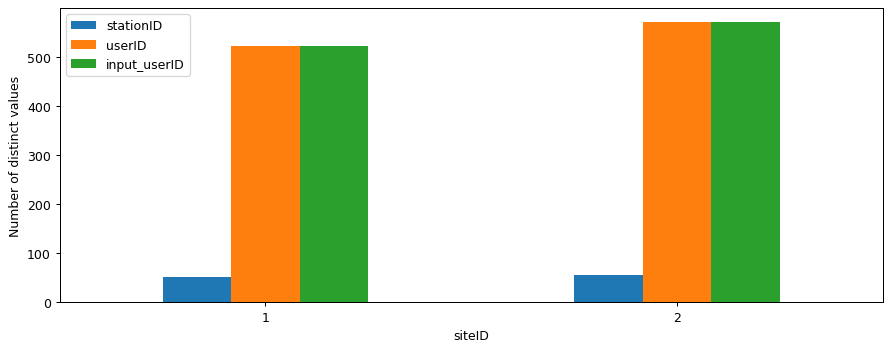

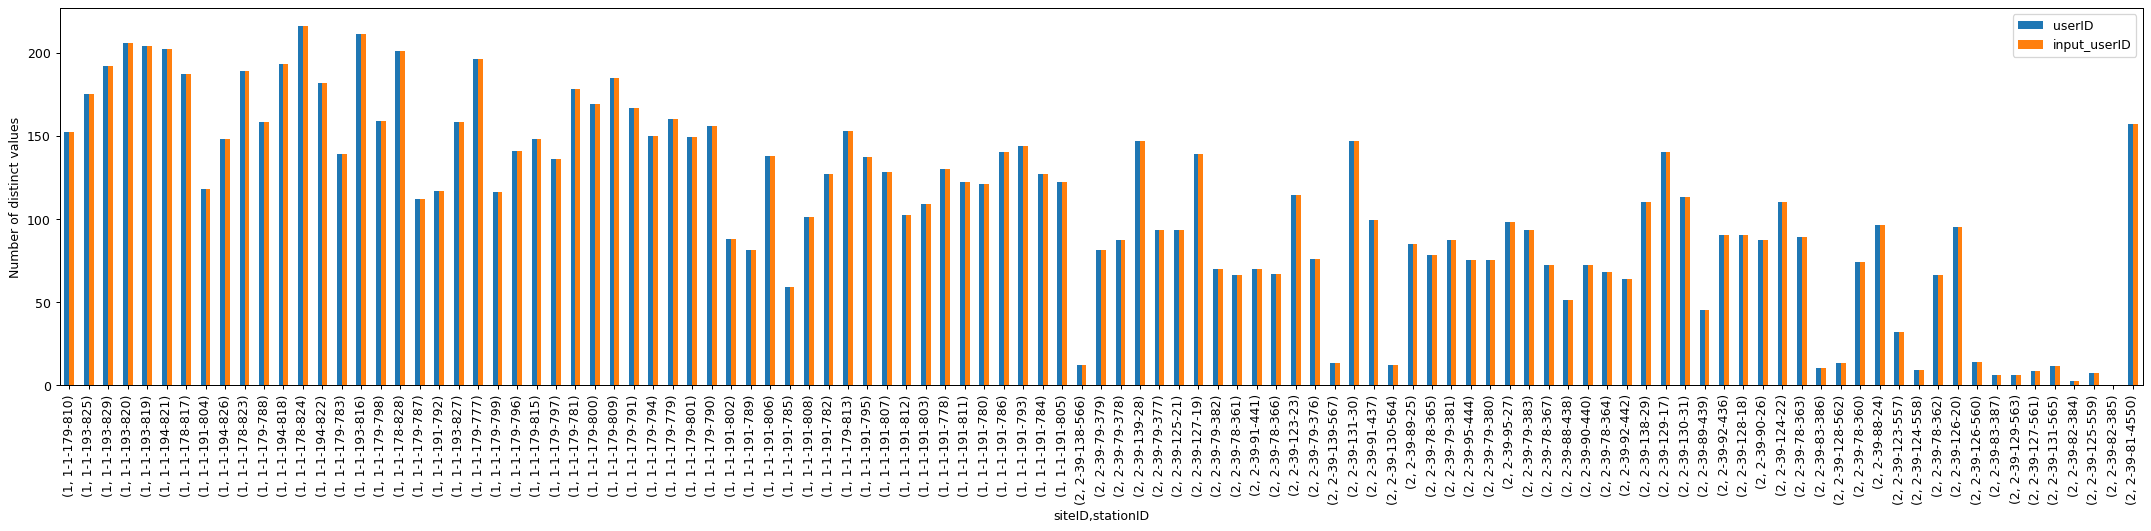

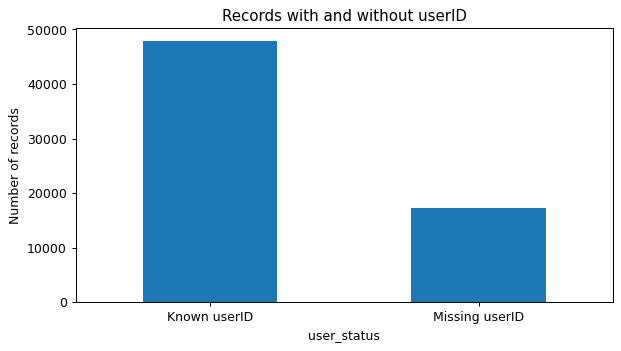

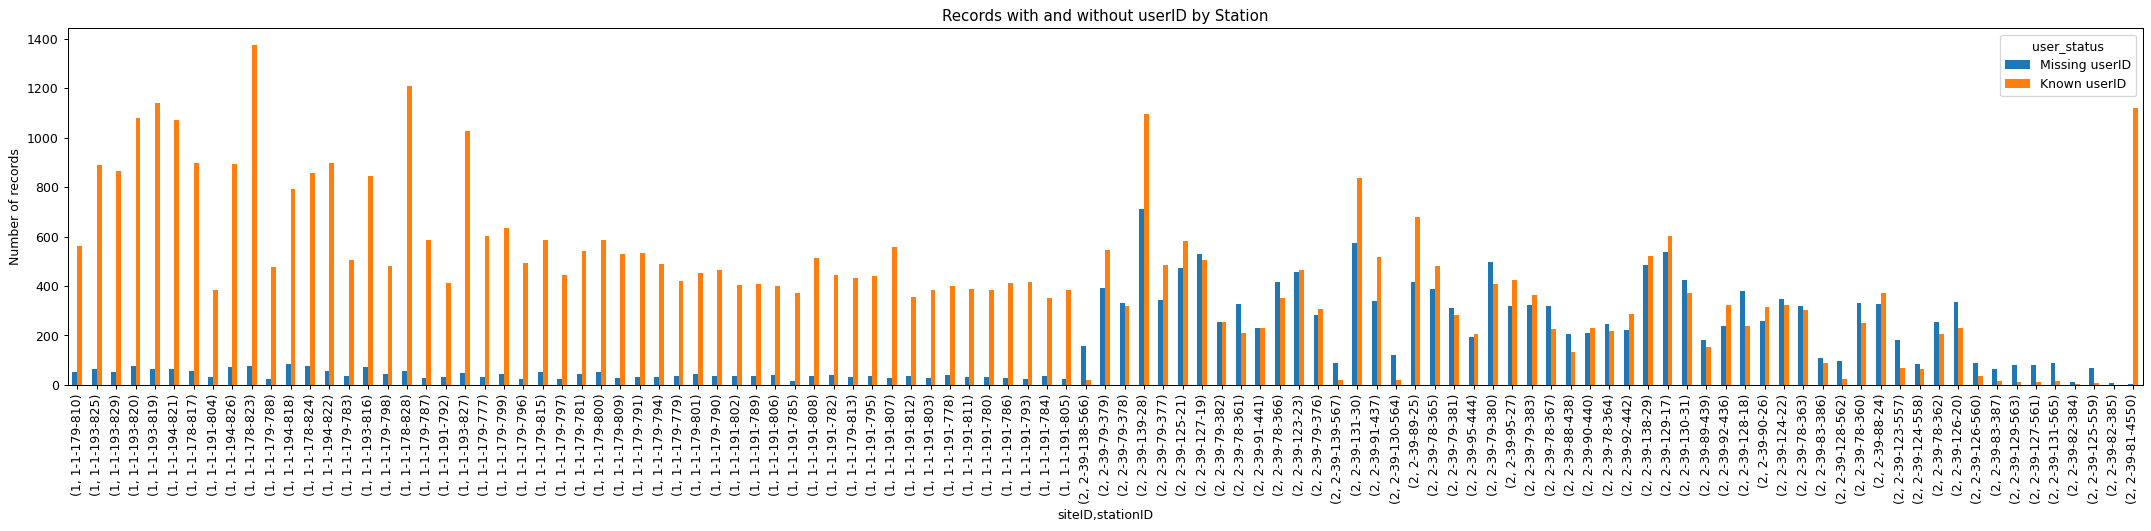

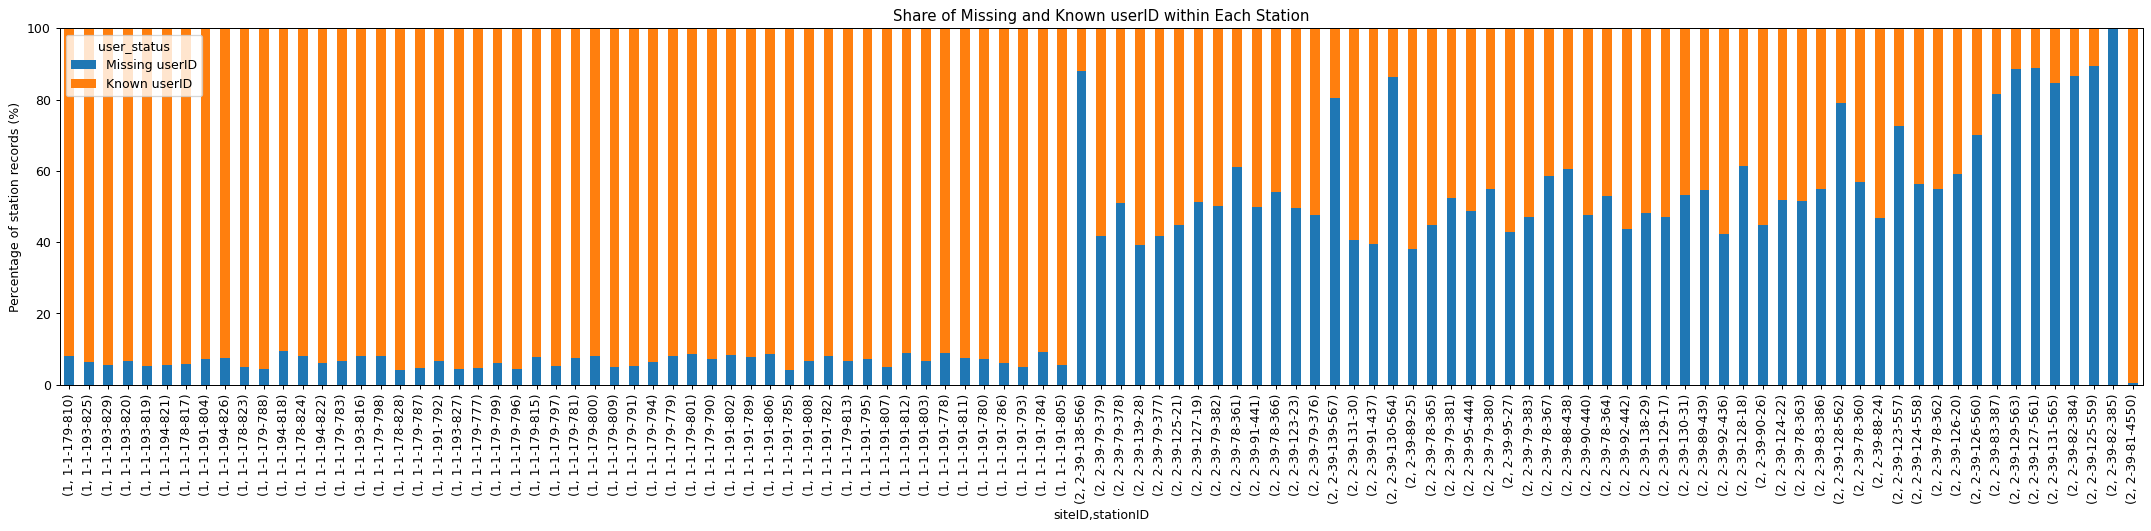

In [7]:
# 2nd check - check for charging location
# Group progressively by site, station, and user.
import matplotlib.pyplot as plt

# Plot by Location
# plot distinct stations and users per site.
charging_sessions.groupby("siteID", sort=False, dropna=False)[
    ["stationID", "userID", "input_userID"]
].nunique().plot.bar(figsize=(10, 4))

plt.ylabel("Number of distinct values")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# plot distinct users per station within each site.
charging_sessions.groupby(["siteID", "stationID"], sort=False, dropna=False)[
    ["userID", "input_userID"]
].nunique().plot.bar(figsize=(24, 6))

plt.ylabel("Number of distinct values")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Plot by whether userID is missing.
data = charging_sessions.assign(
    user_status=charging_sessions["userID"].isna().map({
        True: "Missing userID",
        False: "Known userID"
    })
)

# Compare overall record counts.
data["user_status"].value_counts().plot.bar(
    figsize=(7, 4), rot=0
)
plt.ylabel("Number of records")
plt.title("Records with and without userID")
plt.tight_layout()
plt.show()

# Count records by site, station, and user status.
station_counts = data.groupby(
    ["siteID", "stationID", "user_status"],
    sort=False,
    dropna=False,
    observed=True
).size().unstack("user_status", fill_value=0)

station_counts = station_counts.reindex(
    columns=["Missing userID", "Known userID"], fill_value=0
)

# Compare record counts at each station.
station_counts.plot.bar(figsize=(24, 6))
plt.ylabel("Number of records")
plt.title("Records with and without userID by Station")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Compare percentages within each station.
station_percent = station_counts.div(
    station_counts.sum(axis=1), axis=0
) * 100

station_percent.plot.bar(stacked=True, figsize=(24, 6))
plt.ylabel("Percentage of station records (%)")
plt.title("Share of Missing and Known userID within Each Station")
plt.ylim(0, 100)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Figure interpretation — coverage and identification.**

1. **Distinct points and recorded IDs by site:** infrastructure counts and identification coverage are different quantities. Recorded IDs at site 2 are not treated as verified longitudinal users.
2. **Recorded IDs by charging point:** this shows the distribution of observed identifiers across points, not independent populations; an identifier can occur at several points.
3. **Known versus missing IDs:** anonymous sessions form a substantial part of the dataset and remain in the session-level analysis.
4. **Counts by charging point and ID availability:** absolute counts combine point activity and identification coverage.
5. **Within-point ID proportions:** percentages separate identification coverage from raw activity. Missing IDs must not be combined into one artificial user.

In the cleaned data, missing-ID shares are approximately 6.5% at site 1 and 47.9% at site 2. These observations motivate identified-user analysis at site 1 and session-level analysis at both sites.

Months with no records at either site:
PeriodIndex(['2020-09', '2020-10'], dtype='period[M]', name='Month')


siteID,1,2
Month,,
2018-04,NaN,270.0
2018-05,NaN,1776.0
2018-06,NaN,1845.0
2018-07,NaN,2053.0
2018-08,NaN,2430.0
2018-09,875.0,2315.0
2018-10,1556.0,2424.0
2018-11,1284.0,1309.0
2018-12,1060.0,870.0


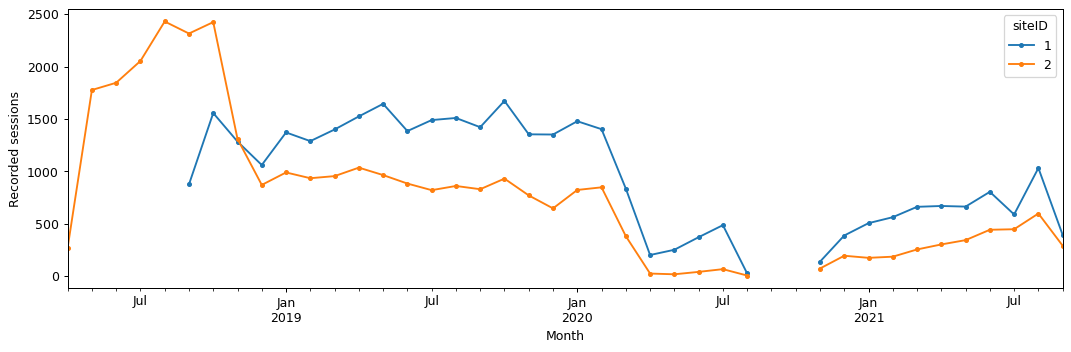

In [8]:
# Monthly record coverage in local time; leave missing months as NaN.
local_month = charging_sessions["connectionTime"].dt.tz_localize(None).dt.to_period("M")
monthly_sessions = charging_sessions.groupby([local_month, "siteID"]).size().unstack()
monthly_sessions = monthly_sessions.reindex(
    pd.period_range(local_month.min(), local_month.max(), freq="M")
)
monthly_sessions.index.name = "Month"
display_table(monthly_sessions)
print("Months with no records at either site:")
display_table(monthly_sessions.index[monthly_sessions.isna().all(axis=1)])
monthly_sessions.plot(figsize=(12, 4), marker=".", ylabel="Recorded sessions")
plt.tight_layout()
plt.show()

**Figure interpretation — monthly record coverage.** The curves show recorded sessions, not independently verified demand. Both sites have no records in September–October 2020; these gaps remain NaN. Low counts during other months may reflect activity changes, operational conditions or collection coverage. The plot alone cannot distinguish these explanations, and the first and last months may be partial.

In [9]:
# Summaries by site, charging point and known user.
group_columns = ["siteID", "stationID", "userID"]
group_results = {}
for level in range(1, len(group_columns) + 1):
    columns = group_columns[:level]
    data = charging_sessions.dropna(subset=["userID"]) if "userID" in columns else charging_sessions
    summary = data.groupby(columns, dropna=False).agg(
        session_count=("sessionID", "size"),
        mean_connected_hours=("connected_duration_hours", "mean"),
        mean_charging_hours=("charging_duration_hours", "mean"),
        valid_charging_duration_count=("charging_duration_hours", "count"),
        mean_energy_kWh=("kWhDelivered", "mean")
    ).reset_index()
    group_results[level] = summary
    print("Grouped by:", ", ".join(columns))
    display_table(summary)

Grouped by: siteID
Grouped by: siteID, stationID
Grouped by: siteID, stationID, userID


,siteID,session_count,mean_connected_hours,mean_charging_hours,valid_charging_duration_count,mean_energy_kWh
0,1,33629,6.856296,4.034588,28384,14.055041
1,2,31408,5.653222,2.884110,28152,9.249425


,siteID,stationID,session_count,mean_connected_hours,mean_charging_hours,valid_charging_duration_count,mean_energy_kWh
0,1,1-1-178-817,953,6.945922,4.633506,789,15.900436
1,1,1-1-178-823,1448,5.754875,3.137417,1217,9.457750
2,1,1-1-178-824,931,6.628656,4.408173,760,14.740947
3,1,1-1-178-828,1265,5.797638,3.456416,1077,11.531034
4,1,1-1-179-777,632,6.994322,4.001127,544,14.622334
5,1,1-1-179-779,456,7.489990,4.731459,395,17.087029
6,1,1-1-179-781,585,7.145652,3.767329,503,14.062233
7,1,1-1-179-783,540,7.373047,4.041931,459,14.641505
8,1,1-1-179-787,612,6.723415,3.828643,538,11.104300
9,1,1-1-179-788,500,7.513429,4.171203,434,14.143551


,siteID,stationID,userID,session_count,mean_connected_hours,mean_charging_hours,valid_charging_duration_count,mean_energy_kWh
0,1,1-1-178-817,000000076,4,1.705833,1.810185,3,6.466750
1,1,1-1-178-817,000000169,1,9.256111,3.431389,1,8.184000
2,1,1-1-178-817,000000171,4,3.696944,2.559028,4,12.529750
3,1,1-1-178-817,000000176,13,9.586581,5.617247,11,15.188462
4,1,1-1-178-817,000000183,1,1.502778,1.500833,1,9.289000
5,1,1-1-178-817,000000194,3,6.859167,4.329259,3,27.229333
6,1,1-1-178-817,000000207,1,2.930278,0.310278,1,1.598000
7,1,1-1-178-817,000000220,2,2.705417,2.418333,2,7.086500
8,1,1-1-178-817,000000313,4,2.062361,1.986667,2,11.727250
9,1,1-1-178-817,000000318,2,3.405417,3.130417,2,8.508500


**Descriptive site comparison.** Across the full available period, mean delivered energy is 14.06 kWh at site 1 and 9.25 kWh at site 2. This is an unadjusted difference: coverage periods and session composition differ. The main comparisons therefore use a common reference period. Recorded-ID summaries at site 2 are data diagnostics, not evidence of validated individual trajectories.

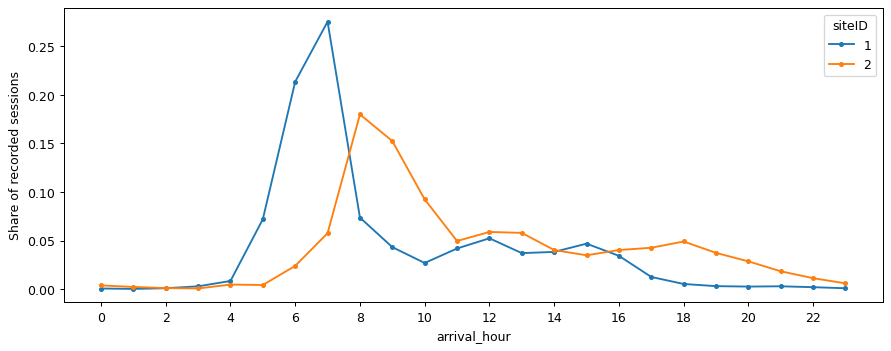

In [10]:
# Local arrival patterns; do not assign a shared ID to anonymous sessions.
charging_sessions["arrival_hour"] = charging_sessions["connectionTime"].dt.hour
charging_sessions["arrival_weekday"] = charging_sessions["connectionTime"].dt.dayofweek
arrival_counts = charging_sessions.groupby(["arrival_hour", "siteID"]).size().unstack()
arrival_counts.div(arrival_counts.sum()).plot(
    figsize=(10, 4), marker=".", ylabel="Share of recorded sessions"
)
plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

**Figure interpretation — local arrival-hour shares.** Each site's curve is normalized by its own recorded session count, so it compares timing rather than total usage. Peaks indicate frequently observed local arrival hours. The figure pools the available period, whereas later clustering uses common dates and distinguishes weekday/weekend patterns. It does not identify trip purposes or occupations.

## Research setup

RQ1: What session types occur independently at each site? Identified-user clustering at site 1 provides a complementary user-level view.

RQ2: How do session-type proportions and within-type characteristics change over time at each site? Site 1 additionally supports matched-user analysis.

RQ3: How well do descriptive patterns and arrival-time prediction models transfer between sites?

The common reference period is September 2018–June 2019. July–September 2019 is used for user-stability diagnostics, and October–December 2019 for held-out comparisons. RQ2 also describes the longer record, with gaps retained. Site 2 is treated as anonymous sessions throughout the main analysis.

In [11]:
import numpy as np
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor

sessions = charging_sessions.loc[
    ~charging_sessions["invalid_connection_time"]
    & charging_sessions["kWhDelivered"].gt(0)
].copy()
sessions["date"] = sessions["connectionTime"].dt.tz_localize(None)
sessions["quarter"] = sessions["date"].dt.to_period("Q")
hour = sessions["date"].dt.hour + sessions["date"].dt.minute / 60
sessions["arrival_sin"] = np.sin(2 * np.pi * hour / 24)
sessions["arrival_cos"] = np.cos(2 * np.pi * hour / 24)
sessions["weekend"] = sessions["date"].dt.dayofweek.ge(5).astype(int)
sessions["month_sin"] = np.sin(2 * np.pi * sessions["date"].dt.month / 12)
sessions["month_cos"] = np.cos(2 * np.pi * sessions["date"].dt.month / 12)

reference_start = pd.Timestamp("2018-09-01")
reference_end = pd.Timestamp("2019-07-01")
stability_end = pd.Timestamp("2019-10-01")
test_end = pd.Timestamp("2020-01-01")
users = sessions.loc[sessions["siteID"].eq(1) & sessions["userID"].notna()].copy()
profile_features = ["arrival_sin", "arrival_cos", "weekend", "duration", "energy", "frequency"]

def user_profiles(data, start, end, minimum=5):
    window = data.loc[data["date"].ge(start) & data["date"].lt(end)]
    profile = window.groupby("userID").agg(
        n=("sessionID", "size"),
        arrival_sin=("arrival_sin", "mean"),
        arrival_cos=("arrival_cos", "mean"),
        weekend=("weekend", "mean"),
        duration=("connected_duration_hours", "mean"),
        energy=("kWhDelivered", "mean")
    )
    profile["frequency"] = profile["n"] / ((end - start).days / 30.4375)
    return profile.loc[profile["n"].ge(minimum)].dropna()

reference = user_profiles(users, reference_start, reference_end, minimum=10)
scaler = StandardScaler()
X = scaler.fit_transform(reference[profile_features])

### RQ1 supplementary analysis — Identified users at site 1

Choose K using reference-period silhouettes only. Compare later profiles using both fixed reference centroids and independently refitted clusters. Labels describe charging behavior, not psychological traits. Frequency means visits recorded at this site, not total charging frequency.

Reference users: 196 Matched future users: 145
Fixed-centroid agreement: 0.903448275862069
Refitted-cluster ARI: 0.6039279002673301


,silhouette
k,
2,0.317085
3,0.278519
4,0.296043
5,0.292762
6,0.289651


,arrival_sin,arrival_cos,weekend,duration,energy,frequency,n
group,,,,,,,
0,-0.111643,-0.622505,0.024386,4.566323,13.185111,4.163252,41.444444
1,0.798384,-0.309711,0.017395,8.379408,16.523317,6.808985,67.782258


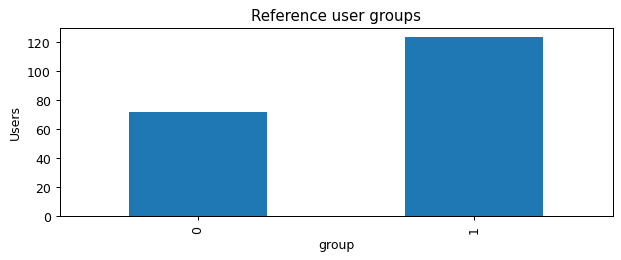

Future,0,1
Reference,,
0,0.903846,0.096154
1,0.096774,0.903226


In [12]:
cluster_models = {}
cluster_scores = []
for k in range(2, min(7, len(reference))):
    model = KMeans(n_clusters=k, random_state=42, n_init=20).fit(X)
    cluster_models[k] = model
    cluster_scores.append({"k": k, "silhouette": silhouette_score(cdist(X, X), model.labels_, metric="precomputed")})
cluster_scores = pd.DataFrame(cluster_scores).set_index("k")
display_table(cluster_scores)
best_k = cluster_scores["silhouette"].idxmax()
cluster_model = cluster_models[best_k]
reference["group"] = cluster_model.labels_
display_table(reference.groupby("group")[profile_features + ["n"]].mean())
reference["group"].value_counts().sort_index().plot.bar(
    figsize=(7, 3), ylabel="Users", title="Reference user groups"
)
plt.tight_layout()
plt.show()

future = user_profiles(users, reference_end, stability_end)
future_X = scaler.transform(future[profile_features])
future["group"] = cluster_model.predict(future_X)
common = reference.index.intersection(future.index)
future_refit = KMeans(n_clusters=best_k, random_state=42, n_init=20).fit(future_X)
refit_labels = pd.Series(future_refit.labels_, index=future.index)
print("Reference users:", len(reference), "Matched future users:", len(common))
print("Fixed-centroid agreement:", reference.loc[common, "group"].eq(future.loc[common, "group"]).mean())
print("Refitted-cluster ARI:", adjusted_rand_score(
    reference.loc[common, "group"], refit_labels.loc[common]
))
display_table(pd.crosstab(reference.loc[common, "group"], future.loc[common, "group"],
                    normalize="index", rownames=["Reference"], colnames=["Future"]))

**Figure interpretation — identified-user group sizes.** The reference sample contains 196 eligible site 1 users: 72 in Group 0 and 124 in Group 1. These are user counts, not session counts. Among 145 users meeting the later-period threshold, fixed-centroid agreement is 90.3%; independently refitted clusters have ARI=0.604. Broad structure persists, but the independently estimated partition is not identical.

### Compare K = 2–6

K=2 is a silhouette-based candidate, not an established number of user types. Compare separation, inertia, group sizes, seed stability and future stability together. Future stability is diagnostic; the final prediction test is not used for choosing K. Cluster numbers are local to each K and cannot be matched by number across solutions.

Heatmaps show standardized feature means; tables retain original units. Arrival sine/cosine jointly describe timing and regularity. Small clusters and overlapping distributions require caution.

,silhouette,inertia,smallest_group,largest_group,mean_seed_ARI,future_fixed_agreement,future_refit_ARI,future_silhouette
k,,,,,,,,
2,0.317,789.828,72,124,1.000,0.903,0.604,0.351
3,0.279,658.918,40,86,0.982,0.890,0.372,0.266
4,0.296,539.722,17,81,0.994,0.834,0.359,0.307
5,0.293,455.754,12,62,0.984,0.779,0.486,0.303
6,0.290,424.474,12,56,0.849,0.690,0.383,0.285


Group,0,1,2,3,4,5
K,,,,,,
2,72,124,0,0,0,0
3,40,86,70,0,0,0
4,17,81,38,60,0,0
5,31,62,42,12,49,0
6,12,50,56,28,31,19


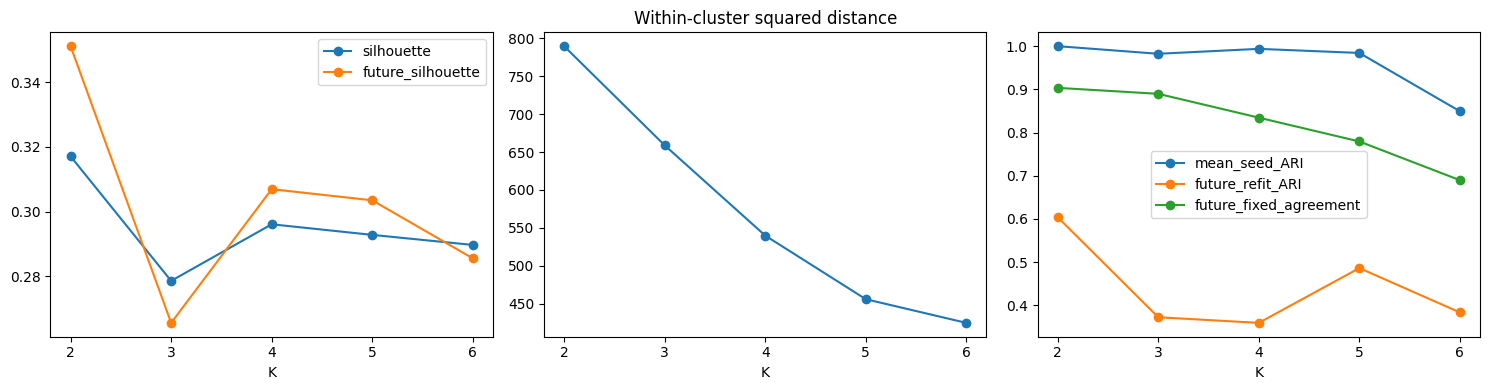

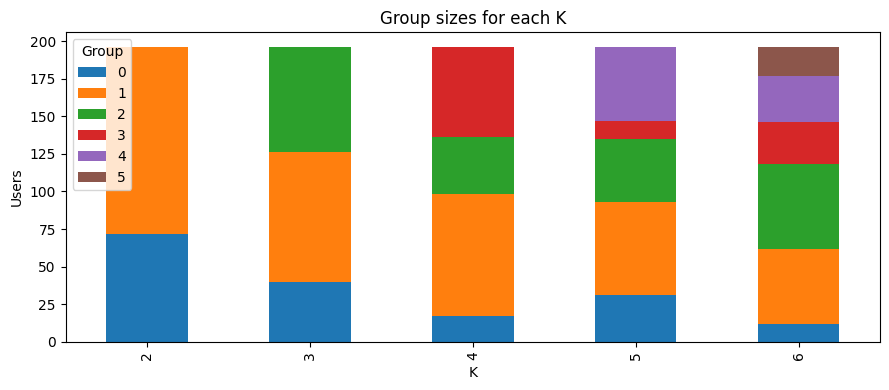

In [ ]:
# Compare all reference-period solutions on the same users and features.
comparison = []
cluster_sizes = {}
user_groups = reference[profile_features + ["n"]].copy()
future_distance = cdist(future_X, future_X)
for k, model in cluster_models.items():
    labels = model.labels_
    sizes = pd.Series(labels).value_counts().sort_index()
    cluster_sizes[k] = sizes
    user_groups[f"group_k{k}"] = labels
    seed_ari = []
    for seed in [0, 1, 2]:
        alternative = KMeans(n_clusters=k, random_state=seed, n_init=20).fit(X)
        seed_ari.append(adjusted_rand_score(labels, alternative.labels_))
    later_labels = model.predict(future_X)
    later_groups = pd.Series(later_labels, index=future.index)
    later_refit = KMeans(n_clusters=k, random_state=42, n_init=20).fit(future_X)
    later_refit = pd.Series(later_refit.labels_, index=future.index)
    comparison.append({
        "k": k, "silhouette": cluster_scores.loc[k, "silhouette"],
        "inertia": model.inertia_, "smallest_group": sizes.min(), "largest_group": sizes.max(),
        "mean_seed_ARI": np.mean(seed_ari),
        "future_fixed_agreement": (user_groups.loc[common, f"group_k{k}"] == later_groups.loc[common]).mean(),
        "future_refit_ARI": adjusted_rand_score(user_groups.loc[common, f"group_k{k}"], later_refit.loc[common]),
        "future_silhouette": silhouette_score(future_distance, later_labels, metric="precomputed")
            if 1 < len(np.unique(later_labels)) < len(later_labels) else np.nan
    })
    # Independently verify distances and fitted labels.
    distance = cdist(X, model.cluster_centers_)
    assert np.isfinite(distance).all()
    assert np.array_equal(distance.argmin(axis=1), labels)
    assert np.isclose((distance[np.arange(len(X)), labels] ** 2).sum(), model.inertia_)
cluster_comparison = pd.DataFrame(comparison).set_index("k")
display_table(cluster_comparison.round(3))
cluster_sizes = pd.DataFrame(cluster_sizes).T.fillna(0).astype(int)
cluster_sizes.index.name = "K"
cluster_sizes.columns.name = "Group"
display_table(cluster_sizes)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cluster_comparison[["silhouette", "future_silhouette"]].plot(marker="o", ax=axes[0])
cluster_comparison["inertia"].plot(marker="o", ax=axes[1], title="Within-cluster squared distance")
cluster_comparison[["mean_seed_ARI", "future_refit_ARI", "future_fixed_agreement"]].plot(marker="o", ax=axes[2])
for ax in axes:
    ax.set_xticks(cluster_comparison.index)
    ax.set_xlabel("K")
plt.tight_layout()
plt.show()
cluster_sizes.plot.bar(stacked=True, figsize=(9, 4), ylabel="Users", title="Group sizes for each K")
plt.tight_layout()
plt.show()

**Figure interpretation — choosing K.** The metric panels compare separation, within-cluster dispersion and stability. K=2 has the highest reference silhouette (0.317); its mean seed ARI is 1.000. Inertia necessarily tends to fall as K increases and is not sufficient evidence for extra groups. The stacked bars show that larger K creates smaller groups, including a 12-user group at K=5. The current two-group choice prioritizes a simple, stable description; it does not establish two natural population types.

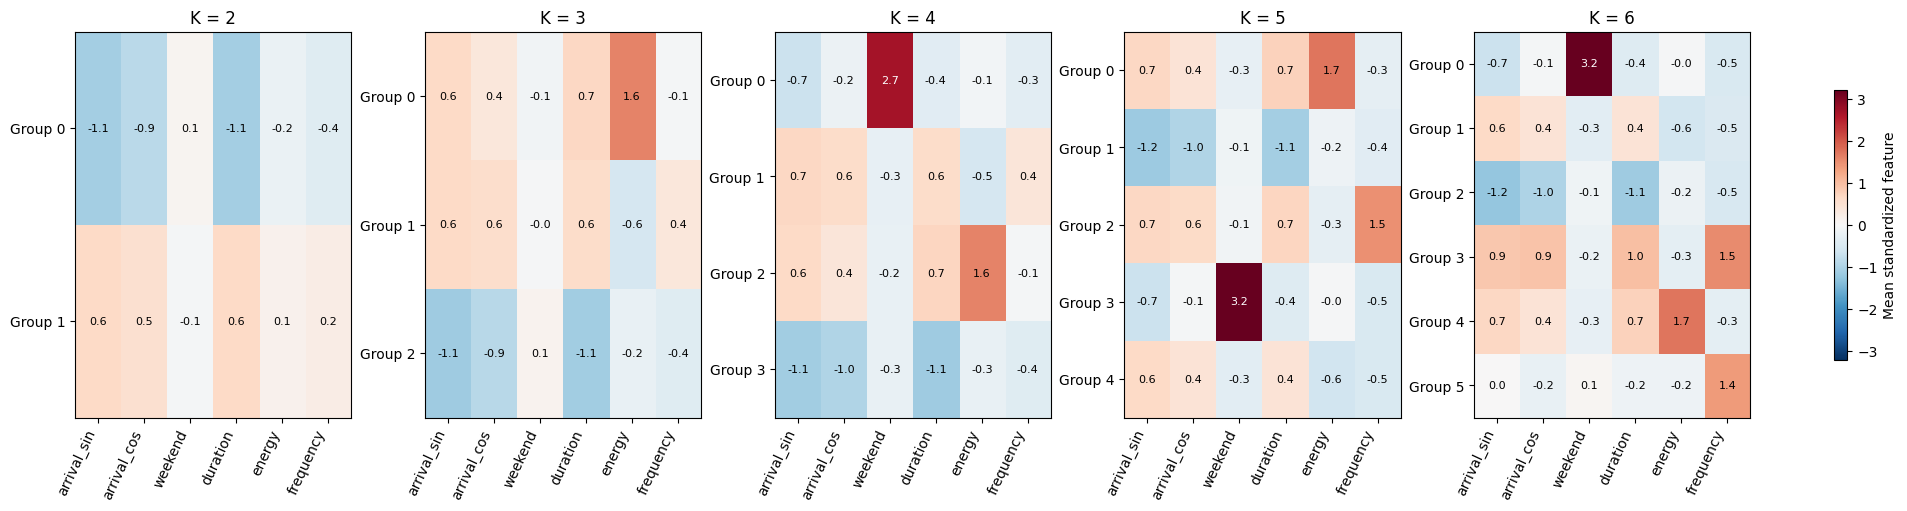

Result table is collapsed. Expand it in an HTML-capable notebook viewer.

In [ ]:
# Standardized user profiles for each K; same color scale in every panel.
profile_tables = {}
standardized_profiles = {}
for k, model in cluster_models.items():
    profile_tables[k] = reference[profile_features].assign(group=model.labels_).groupby("group").mean()
    standardized_profiles[k] = pd.DataFrame(X, columns=profile_features).assign(
        group=model.labels_
    ).groupby("group").mean()

limit = max(abs(table.to_numpy()).max() for table in standardized_profiles.values())
fig, axes = plt.subplots(1, len(cluster_models), figsize=(19, 5), constrained_layout=True)
for ax, (k, table) in zip(axes, standardized_profiles.items()):
    plot = ax.imshow(table, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
    ax.set_title(f"K = {k}")
    ax.set_xticks(range(len(profile_features)), profile_features, rotation=65, ha="right")
    ax.set_yticks(range(k), [f"Group {g}" for g in table.index])
    for row in range(k):
        for column in range(len(profile_features)):
            value = table.iloc[row, column]
            ax.text(column, row, f"{value:.1f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(value) > limit * 0.6 else "black")
fig.colorbar(plot, ax=list(axes), label="Mean standardized feature", shrink=0.7)
plt.show()

# Raw feature means and user counts, for interpretation.
profile_summary = pd.concat(profile_tables, names=["K", "group"])
profile_summary["users"] = pd.Series({(k, g): count for k, sizes in cluster_sizes.iterrows()
                                      for g, count in sizes.items() if count > 0})
display_table(profile_summary.round(2))

**Figure interpretation — standardized user profiles.** Colors represent feature means relative to the same reference-user standardization, allowing comparison across K. At K=3, the early-arrival/long-connection pattern splits into groups with mean energy of approximately 30.82 and 9.91 kWh, despite similar mean connection durations around 8.3–8.4 hours. Thus, similar connection schedules need not imply similar energy requirements. Cluster numbers are not aligned across K.

Users: 196 Reference period: 2018-09-01 to 2019-07-01
Silhouette-based candidate K: 2 — downstream analyses retain this candidate until the comparison is reviewed.


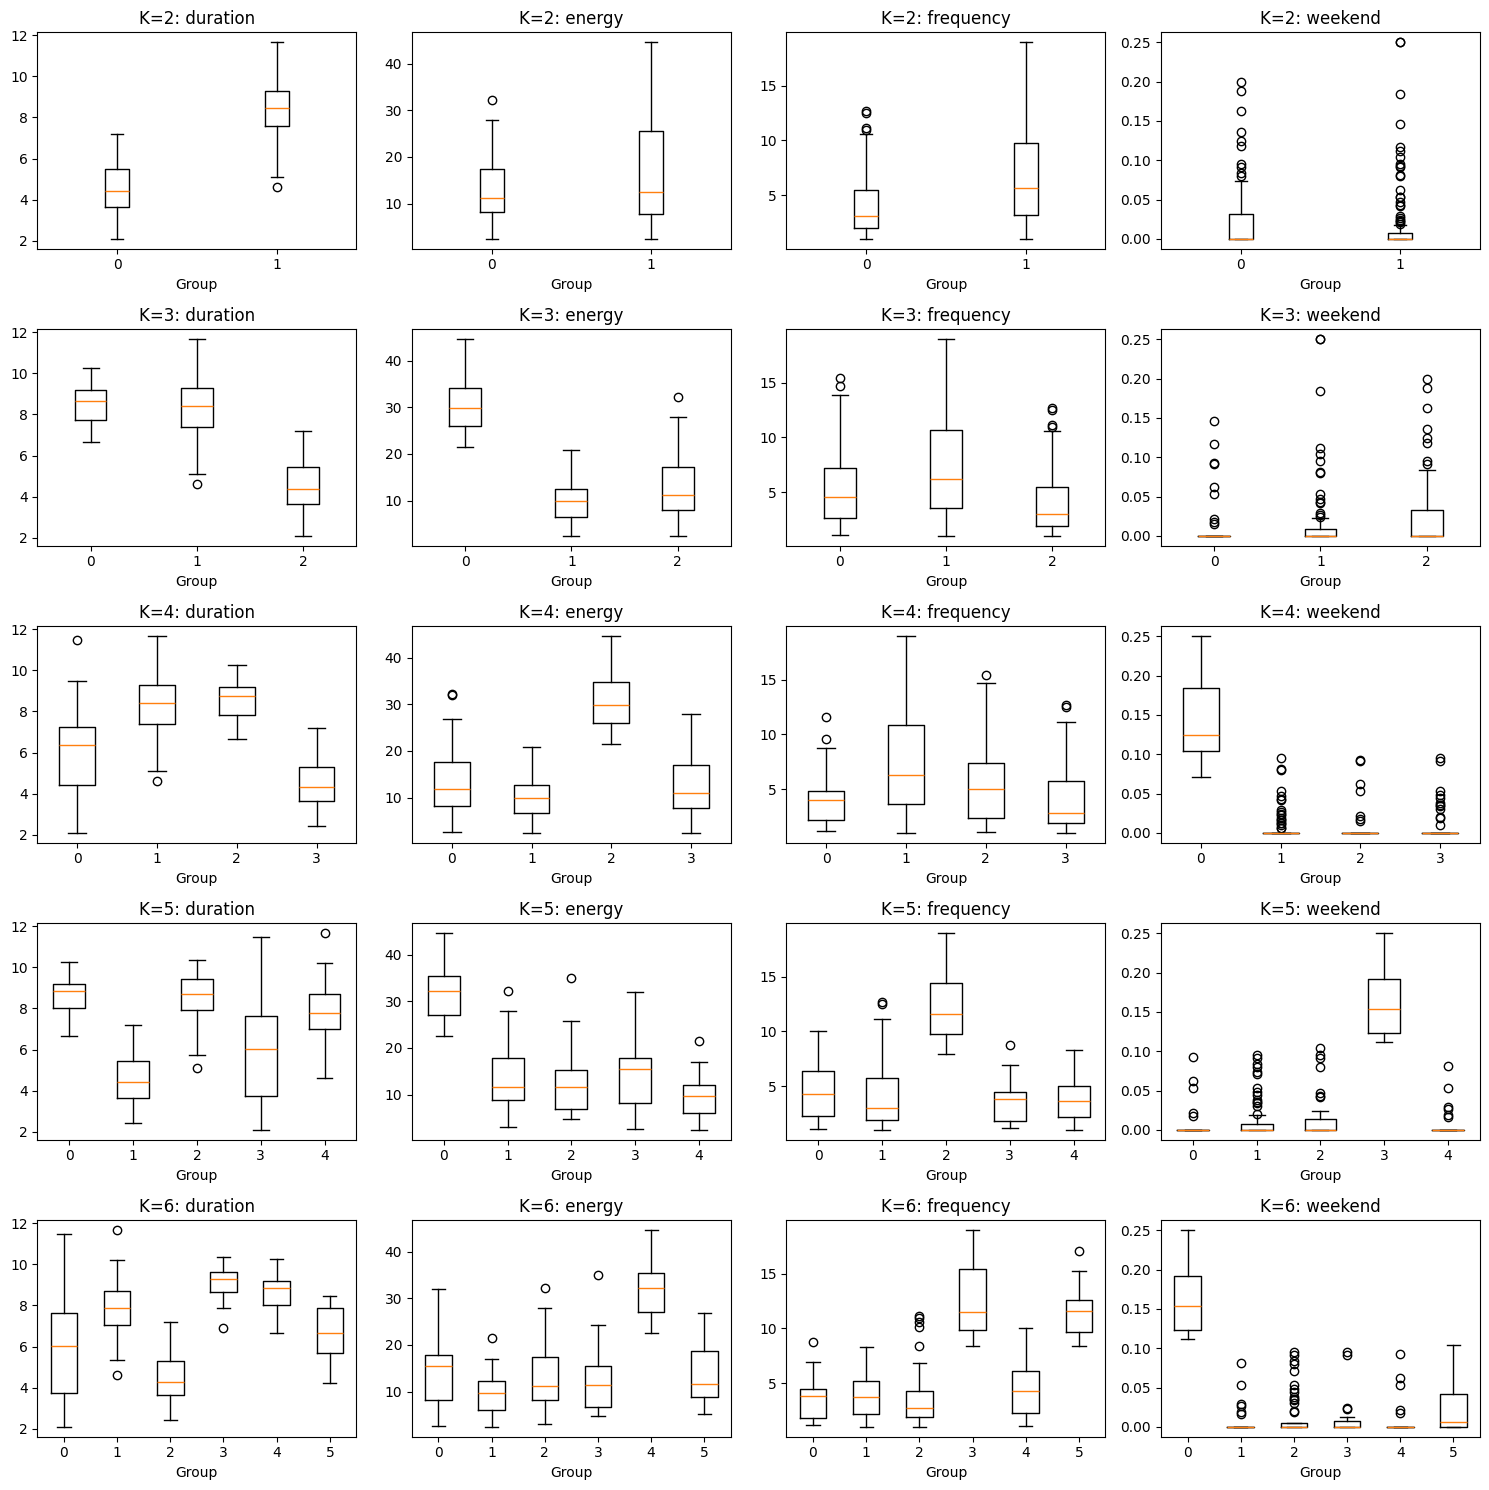

,arrival_sin,arrival_cos,weekend,duration,energy,frequency,n,group_k2,group_k3,group_k4,group_k5,group_k6
userID,,,,,,,,,,,,
000000076,-0.524739,-0.692072,0.095238,2.402923,6.294083,8.438119,84,0,2,3,1,2
000000449,-0.304250,0.061949,0.136364,3.702790,16.018318,2.209983,22,0,2,0,3,0
000000448,-0.545354,-0.607180,0.117647,3.735327,16.080471,1.707715,17,0,2,0,3,0
000000438,-0.016438,-0.334700,0.188406,4.426425,18.440232,6.931312,69,0,2,0,3,0
000000428,0.396629,-0.635783,0.000000,5.215601,11.802876,10.547649,105,0,2,3,1,5
000000420,-0.308319,-0.775917,0.000000,2.911751,9.754757,10.547649,105,0,2,3,1,2
000001485,-0.628351,-0.586316,0.000000,2.793340,9.954846,3.917698,39,0,2,3,1,2
000001564,0.525705,-0.570539,0.000000,5.925937,5.067250,3.214521,32,0,2,3,4,1
000000413,-0.190428,-0.660951,0.200000,3.258951,8.253225,4.018152,40,0,2,0,3,0


In [ ]:
# Distribution overlap: compare all K, rather than only group averages.
box_features = ["duration", "energy", "frequency", "weekend"]
fig, axes = plt.subplots(len(cluster_models), len(box_features), figsize=(15, 15))
for row, (k, model) in enumerate(cluster_models.items()):
    for column, feature in enumerate(box_features):
        ax = axes[row, column]
        values = [reference.loc[model.labels_ == group, feature] for group in range(k)]
        ax.boxplot(values, labels=list(range(k)), showfliers=True)
        ax.set_title(f"K={k}: {feature}")
        ax.set_xlabel("Group")
plt.tight_layout()
plt.show()

# All eligible reference users and assignments under every K.
print("Users:", len(user_groups), "Reference period:", reference_start.date(), "to", reference_end.date())
with pd.option_context("display.max_rows", None):
    display_table(user_groups.sort_values(f"group_k{best_k}"))
print("Silhouette-based candidate K:", best_k,
      "— downstream analyses retain this candidate until the comparison is reviewed.")

**Figure interpretation — within-group distributions.** Each row uses a different K; columns compare duration, energy, recorded frequency and weekend share. Boxes describe medians and interquartile ranges, while displayed outliers reveal long tails. Use these distributions to assess overlap rather than interpreting different group means as perfect separation. Finer groups may reveal additional heterogeneity but require adequate sample sizes and temporal validation.

### Selected behavioral groups

This exploratory analysis retains K=2: it has the highest reference-period silhouette (0.317), with 72 and 124 users. Mean agreement with the reference solution across three alternative random seeds is ARI=1.000. Among 145 matched users in the later period, fixed-centroid label agreement is 90.3%. Temporal stability is supplementary evidence, not confirmation of true latent user types.

K=3–5 provides finer distinctions in energy, visit frequency and weekend use and remains available for sensitivity analysis. K=2 is the current parsimonious baseline, not evidence that only two user types exist. The labels describe observed behavior at site 1; they do not establish occupation, trip purpose, psychological preferences or activity at other charging sites.

In [ ]:
# Explain the selected solution in original units (equal weight per user).
selected_k = best_k
selected_profiles = reference[profile_features].assign(
    group=cluster_models[selected_k].labels_
).groupby("group").mean()
selected_profiles["users"] = pd.Series(cluster_models[selected_k].labels_).value_counts()
selected_profiles["share_pct"] = selected_profiles["users"] / len(reference) * 100
selected_profiles["arrival_hour_circular"] = (
    np.arctan2(selected_profiles["arrival_sin"], selected_profiles["arrival_cos"])
    % (2 * np.pi)
) * 24 / (2 * np.pi)
selected_profiles["arrival_concentration"] = np.hypot(
    selected_profiles["arrival_sin"], selected_profiles["arrival_cos"]
)
selected_profiles["weekend_pct"] = selected_profiles["weekend"] * 100

# Names are relative descriptions; cluster numbers themselves carry no meaning.
if selected_k == 2:
    short_group = selected_profiles["duration"].idxmin()
    long_group = selected_profiles["duration"].idxmax()
    group_names = {
        short_group: "Later arrival / shorter connection / less frequent visits",
        long_group: "Morning arrival / longer connection / more frequent visits"
    }
else:
    group_names = {group: f"Behavioral group {group}" for group in selected_profiles.index}
selected_profiles.insert(0, "behavior_label", selected_profiles.index.map(group_names))
display_table(selected_profiles[["behavior_label", "users", "share_pct", "arrival_hour_circular",
    "arrival_concentration", "duration", "energy", "frequency", "weekend_pct"]].round(2))
reference["behavior_label"] = reference["group"].map(group_names)
user_groups["selected_group"] = reference["group"]
user_groups["behavior_label"] = reference["behavior_label"]
with pd.option_context("display.max_rows", None):
    display_table(user_groups.sort_values("selected_group"))

,behavior_label,users,share_pct,arrival_hour_circular,arrival_concentration,duration,energy,frequency,weekend_pct
group,,,,,,,,,
0,Later arrival / shorter connection / less frequent visits,72,36.73,12.68,0.63,4.57,13.19,4.16,2.44
1,Morning arrival / longer connection / more frequent visits,124,63.27,7.41,0.86,8.38,16.52,6.81,1.74


,arrival_sin,arrival_cos,weekend,duration,energy,frequency,n,group_k2,group_k3,group_k4,group_k5,group_k6,selected_group,behavior_label
userID,,,,,,,,,,,,,,
000000076,-0.524739,-0.692072,0.095238,2.402923,6.294083,8.438119,84,0,2,3,1,2,0,Later arrival / shorter connection / less frequent visits
000000449,-0.304250,0.061949,0.136364,3.702790,16.018318,2.209983,22,0,2,0,3,0,0,Later arrival / shorter connection / less frequent visits
000000448,-0.545354,-0.607180,0.117647,3.735327,16.080471,1.707715,17,0,2,0,3,0,0,Later arrival / shorter connection / less frequent visits
000000438,-0.016438,-0.334700,0.188406,4.426425,18.440232,6.931312,69,0,2,0,3,0,0,Later arrival / shorter connection / less frequent visits
000000428,0.396629,-0.635783,0.000000,5.215601,11.802876,10.547649,105,0,2,3,1,5,0,Later arrival / shorter connection / less frequent visits
000000420,-0.308319,-0.775917,0.000000,2.911751,9.754757,10.547649,105,0,2,3,1,2,0,Later arrival / shorter connection / less frequent visits
000001485,-0.628351,-0.586316,0.000000,2.793340,9.954846,3.917698,39,0,2,3,1,2,0,Later arrival / shorter connection / less frequent visits
000001564,0.525705,-0.570539,0.000000,5.925937,5.067250,3.214521,32,0,2,3,4,1,0,Later arrival / shorter connection / less frequent visits
000000413,-0.190428,-0.660951,0.200000,3.258951,8.253225,4.018152,40,0,2,0,3,0,0,Later arrival / shorter connection / less frequent visits


**Group 0: Later arrival, shorter connection, less frequent visits (72 users; 36.7%).** Average connection duration is 4.57 hours, delivered energy is 13.19 kWh per session, and recorded visit frequency is 4.16 sessions per month. The circular mean arrival time is approximately 12:41, with concentration 0.63. Arrival times are comparatively dispersed; the mean does not imply that every user arrives at noon.

**Group 1: Morning arrival, longer connection, more frequent visits (124 users; 63.3%).** Average connection duration is 8.38 hours, delivered energy is 16.52 kWh per session, and recorded visit frequency is 6.81 sessions per month. The circular mean arrival time is approximately 07:25, with concentration 0.86. This pattern is compatible with extended weekday parking, but occupation and trip purpose are not observed.

**The main distinctions are arrival timing, connection duration and recorded visit frequency.** Both groups predominantly use the site on weekdays: their mean weekend session shares are 2.44% and 1.74%. Weekend use is therefore not a defining distinction between these two groups. Different mean energy values do not imply non-overlapping distributions; inspect the boxplots alongside the means.

All summaries weight users equally. Arrival concentration is the length of the mean sine/cosine vector, ranging from 0 to 1; it reflects both within-user and between-user timing variation, not a psychological score. Connection duration is not active charging duration, and visit frequency excludes other sites. These interpretations correspond to the current run and should be reviewed if the data or K changes.

In [13]:
# Future energy prediction: same test users and sessions for all baselines.
reference_sessions = users.loc[
    users["date"].ge(reference_start) & users["date"].lt(reference_end)
].join(reference["group"], on="userID").dropna(subset=["group"])
group_energy = reference_sessions.groupby("group")["kWhDelivered"].mean()
test_users = users.loc[
    users["date"].ge(stability_end) & users["date"].lt(test_end)
    & users["userID"].isin(reference.index)
].copy()
predictions = {
    "Global mean": np.repeat(reference_sessions["kWhDelivered"].mean(), len(test_users)),
    "Group mean": test_users["userID"].map(reference["group"]).map(group_energy),
    "Personal mean": test_users["userID"].map(reference["energy"])
}
rq1_scores = []
for name, prediction in predictions.items():
    error = pd.Series(np.abs(test_users["kWhDelivered"].to_numpy() - np.asarray(prediction)),
                      index=test_users.index)
    rq1_scores.append({"model": name, "session_MAE_kWh": error.mean(),
                       "user_macro_MAE_kWh": error.groupby(test_users["userID"]).mean().mean()})
print("Test sessions:", len(test_users), "Test users:", test_users["userID"].nunique())
display_table(pd.DataFrame(rq1_scores).set_index("model"))

Test sessions: 3078 Test users: 161


,session_MAE_kWh,user_macro_MAE_kWh
model,,
Global mean,8.312237,9.191978
Group mean,8.251816,9.010026
Personal mean,4.570294,5.431058


**Prediction finding — user history versus coarse groups.** On the same 3,078 test sessions from 161 reference users, MAE is 8.31 kWh for the global mean, 8.25 for group means and 4.57 for personal historical means. Group means improve little, whereas personal history reduces session-weighted MAE by about 45% relative to the global mean. The two-group description therefore retains limited information for energy prediction; substantial heterogeneity remains within groups. This result applies to previously observed eligible users, not new or anonymous users.

## RQ1 main analysis — Separate session clustering by site

The earlier analysis clusters identified users at site 1 only. This section independently clusters charging sessions at each site, including anonymous sessions. A session type is not a user type: one person can generate several session types. Both sites use the same reference dates and features, but separate scalers, centroids and K selection. Cluster numbers are not aligned across sites.

Connection duration and delivered energy are log-transformed before scaling to reduce the influence of long-tailed values. Silhouettes use the same fixed sample of up to 2,000 sessions within each site for all K. These are descriptive reference-period clusters, not predictions or causal explanations. Session proportions weight frequent users more heavily.

Result table is collapsed. Expand it in an HTML-capable notebook viewer.

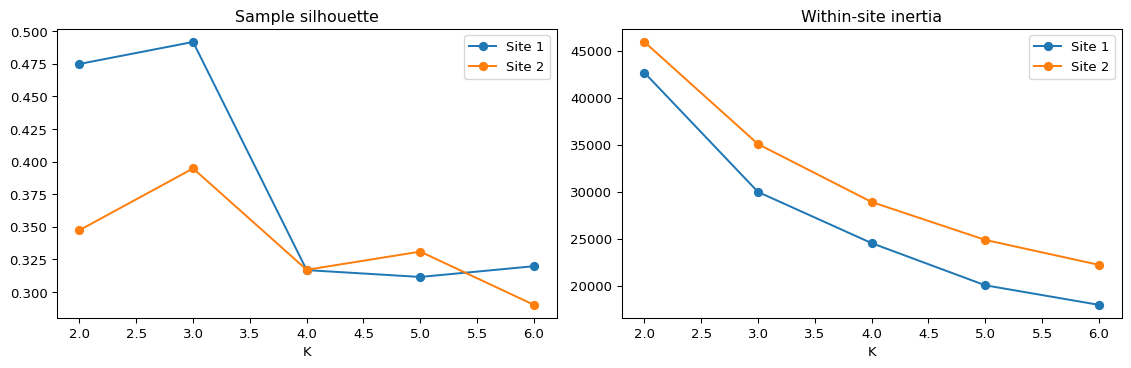

In [ ]:
# Independent session models: no user ID or combined-site fitting.
site_models = {}
site_profiles = {}
site_assignments = {}
site_candidates = []
session_features = ["arrival_sin", "arrival_cos", "weekend", "log_duration", "log_energy"]
for site in [1, 2]:
    data = sessions.loc[
        sessions["siteID"].eq(site)
        & sessions["date"].ge(reference_start) & sessions["date"].lt(reference_end)
        & sessions["connected_duration_hours"].gt(0)
    ].copy()
    data["log_duration"] = np.log1p(data["connected_duration_hours"])
    data["log_energy"] = np.log1p(data["kWhDelivered"])
    site_scaler = StandardScaler()
    values = site_scaler.fit_transform(data[session_features])
    rng = np.random.default_rng(42)
    sample = rng.choice(len(data), size=min(2000, len(data)), replace=False)
    distances = cdist(values[sample], values[sample])
    candidates = {}
    for k in range(2, 7):
        model = KMeans(n_clusters=k, init="random", n_init=20, random_state=42).fit(values)
        candidates[k] = model
        counts = np.bincount(model.labels_, minlength=k)
        score = silhouette_score(distances, model.labels_[sample], metric="precomputed")
        site_candidates.append({"site": site, "k": k, "silhouette": score,
                                "inertia": model.inertia_, "smallest_cluster": counts.min(),
                                "largest_cluster": counts.max()})
    scores = pd.DataFrame(site_candidates).query("site == @site")
    selected = int(scores.loc[scores["silhouette"].idxmax(), "k"])
    model = candidates[selected]
    data["session_group"] = model.labels_
    site_models[site] = {"k": selected, "scaler": site_scaler, "model": model}
    profile = data.groupby("session_group").agg(
        sessions=("sessionID", "size"), arrival_sin=("arrival_sin", "mean"),
        arrival_cos=("arrival_cos", "mean"), weekend_share=("weekend", "mean"),
        mean_connected_hours=("connected_duration_hours", "mean"),
        median_connected_hours=("connected_duration_hours", "median"),
        mean_energy_kWh=("kWhDelivered", "mean"), median_energy_kWh=("kWhDelivered", "median")
    )
    profile["share_pct"] = profile["sessions"] / len(data) * 100
    profile["circular_arrival_hour"] = np.arctan2(profile["arrival_sin"], profile["arrival_cos"]) % (2*np.pi) * 24/(2*np.pi)
    profile["arrival_concentration"] = np.hypot(profile["arrival_sin"], profile["arrival_cos"])
    descriptions = {}
    for group, row in profile.iterrows():
        hour = row["circular_arrival_hour"]
        timing = "morning" if 5 <= hour < 12 else "afternoon" if 12 <= hour < 18 else "evening/night"
        if row["arrival_concentration"] < 0.4:
            timing = "dispersed arrival times"
        duration = "longer connections" if row["median_connected_hours"] >= data["connected_duration_hours"].median() else "shorter connections"
        energy = "higher delivered energy" if row["median_energy_kWh"] >= data["kWhDelivered"].median() else "lower delivered energy"
        day = "mostly weekdays" if row["weekend_share"] < 0.2 else "mostly weekends" if row["weekend_share"] > 0.8 else "mixed weekdays/weekends"
        descriptions[group] = f"{timing}; {duration}; {energy}; {day}"
    profile["behavior_description"] = pd.Series(descriptions)
    data["behavior_description"] = data["session_group"].map(descriptions)
    site_profiles[site] = profile
    site_assignments[site] = data

site_comparison = pd.DataFrame(site_candidates).set_index(["site", "k"])
display_table(site_comparison.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for site in [1, 2]:
    result = site_comparison.loc[site]
    axes[0].plot(result.index, result["silhouette"], marker="o", label=f"Site {site}")
    axes[1].plot(result.index, result["inertia"], marker="o", label=f"Site {site}")
for ax, title in zip(axes, ["Sample silhouette", "Within-site inertia"]):
    ax.set_title(title)
    ax.set_xlabel("K")
    ax.legend()
plt.tight_layout()
plt.show()

**Figure interpretation — independent site-level K selection.** Both sites select K=3 within the tested range. Sample silhouettes are 0.492 at site 1 and 0.395 at site 2. Each site's curve uses its own fixed evaluation sample and scaler; absolute inertia is not a direct measure of which site has a better model. The weekend feature strongly affects the partition, so a feature-weight or weekend-exclusion sensitivity analysis is needed before interpreting the three groups as robust latent types.

Site 1: K=3, sessions=13385
Descriptions are relative to this site's median duration and energy.
Site 2: K=3, sessions=12677
Descriptions are relative to this site's median duration and energy.


,sessions,weekend_share,mean_connected_hours,median_connected_hours,mean_energy_kWh,median_energy_kWh,share_pct,circular_arrival_hour,arrival_concentration,behavior_description
session_group,,,,,,,,,,
0,9308,0.0,8.85,9.33,15.16,11.82,69.54,7.06,0.96,morning; longer connections; higher delivered energy; mostly weekdays
1,3753,0.0,3.39,3.07,9.96,8.18,28.04,13.84,0.78,afternoon; shorter connections; lower delivered energy; mostly weekdays
2,324,1.0,4.45,3.97,11.42,9.56,2.42,11.33,0.65,morning; shorter connections; lower delivered energy; mostly weekends


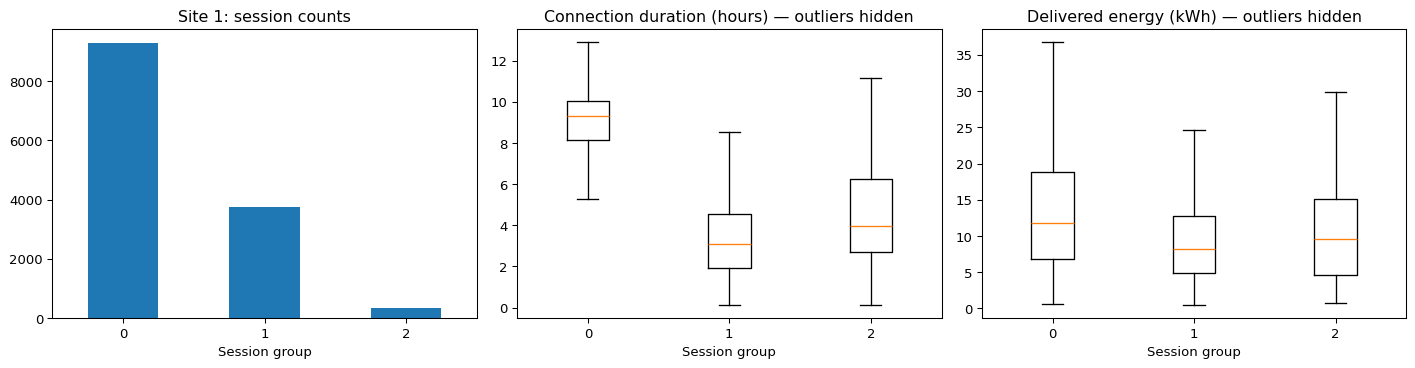

,sessions,weekend_share,mean_connected_hours,median_connected_hours,mean_energy_kWh,median_energy_kWh,share_pct,circular_arrival_hour,arrival_concentration,behavior_description
session_group,,,,,,,,,,
0,1979,1.0,4.36,2.29,9.80,7.30,15.61,13.36,0.51,afternoon; shorter connections; higher delivered energy; mostly weekends
1,7942,0.0,7.24,7.59,9.24,7.03,62.65,9.55,0.88,morning; longer connections; higher delivered energy; mostly weekdays
2,2756,0.0,4.08,1.97,8.56,6.36,21.74,18.29,0.81,evening/night; shorter connections; lower delivered energy; mostly weekdays


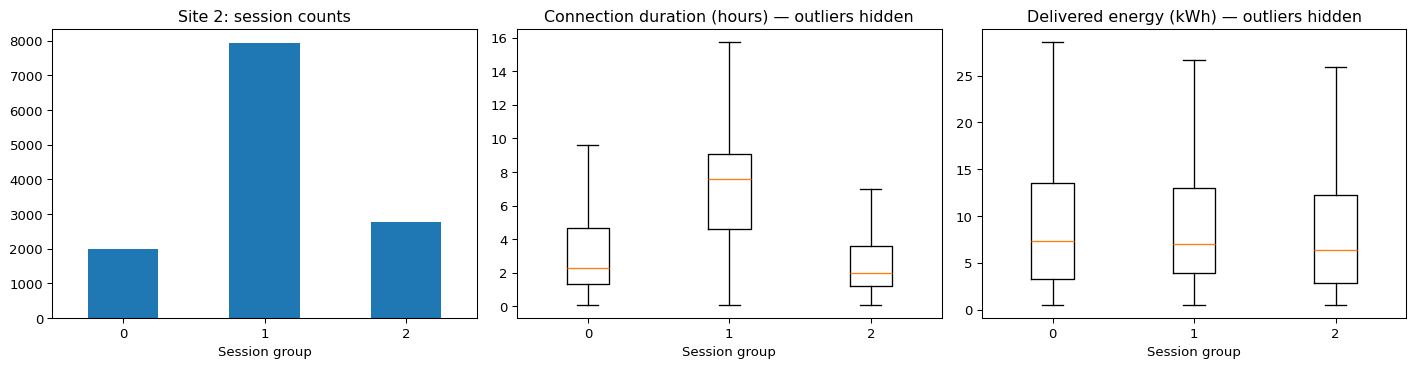

Result table is collapsed. Expand it in an HTML-capable notebook viewer.

In [ ]:
# Results and behavioral descriptions shown separately for each site.
for site in [1, 2]:
    profile = site_profiles[site]
    data = site_assignments[site]
    print(f"Site {site}: K={site_models[site]['k']}, sessions={len(data)}")
    print("Descriptions are relative to this site's median duration and energy.")
    with pd.option_context("display.max_colwidth", None):
        display_table(profile.drop(columns=["arrival_sin", "arrival_cos"]).round(2))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    profile["sessions"].plot.bar(ax=axes[0], title=f"Site {site}: session counts", rot=0)
    for ax, feature, title in [(axes[1], "connected_duration_hours", "Connection duration (hours)"),
                                (axes[2], "kWhDelivered", "Delivered energy (kWh)")]:
        groups = [data.loc[data["session_group"].eq(group), feature] for group in profile.index]
        ax.boxplot(groups, labels=profile.index.tolist(), showfliers=False)
        ax.set_title(title + " — outliers hidden")
    for ax in axes:
        ax.set_xlabel("Session group")
    plt.tight_layout()
    plt.show()

# Side-by-side comparison in original units; labels are site-specific.
site_profile_comparison = pd.concat(site_profiles, names=["site", "session_group"])
display_table(site_profile_comparison[["sessions", "share_pct", "circular_arrival_hour",
    "arrival_concentration", "median_connected_hours", "median_energy_kWh", "weekend_share"]].round(2))
# All assignments remain available in site_assignments[1] and site_assignments[2].

**Figure interpretation — separate session types.**

- **Site 1:** weekday morning/long-connection sessions account for 69.54%, weekday afternoon/shorter sessions for 28.04%, and weekend sessions for 2.42%. Median connection durations are 9.33, 3.07 and 3.97 hours, respectively.
- **Site 2:** weekday morning/long-connection sessions account for 62.65%, weekday evening/shorter sessions for 21.74%, and weekend sessions for 15.61%. Median durations are 7.59, 1.97 and 2.29 hours, respectively.

Bars count sessions, not unique people. Boxplots compare original-unit distributions; outlier markers are hidden for readability but observations remain in the analysis. The sites share an early-arrival/long-connection pattern, while non-morning timing and weekend shares differ. A weekend cluster partly reflects the explicitly included weekday/weekend feature.

### How to interpret the site-specific results

Read each site's selected K, cluster sizes, original-unit profiles and descriptions together. The labels summarize observed session characteristics; they do not identify occupations, motives, unique people or battery needs. Duration and energy labels compare cluster medians with the corresponding whole-site median, so they are relative rather than universal thresholds.

The two sites have independent feature scaling and cluster boundaries. Group 0 at site 1 is not necessarily equivalent to Group 0 at site 2. Compare the original-unit profiles rather than matching group numbers. Rare weekend sessions can form a separate cluster after standardization; inspect weekend shares and cluster sizes before claiming a substantively distinct behavioral type. The selected K remains exploratory and should be checked across time windows.

## RQ2 — Temporal changes in session types at each site

Assign later sessions using each site's fixed reference-period scaler and centroids. Plot monthly type shares and within-type median energy and connection duration. These are changes in observed sessions, not movements of identified users. Missing months remain missing. The first and last months can have partial coverage; recorded-month completeness is not guaranteed. The user-level analysis below is supplementary and applies only to identified site 1 users.

Site 1: monthly session counts by fixed type
Site 2: monthly session counts by fixed type


session_group,0,1,2
2018-09,570.0,279.0,26.0
2018-10,1095.0,427.0,34.0
2018-11,907.0,350.0,27.0
2018-12,747.0,296.0,17.0
2019-01,1002.0,347.0,22.0
2019-02,916.0,349.0,23.0
2019-03,974.0,389.0,36.0
2019-04,1062.0,442.0,20.0
2019-05,1066.0,499.0,79.0
2019-06,969.0,375.0,40.0


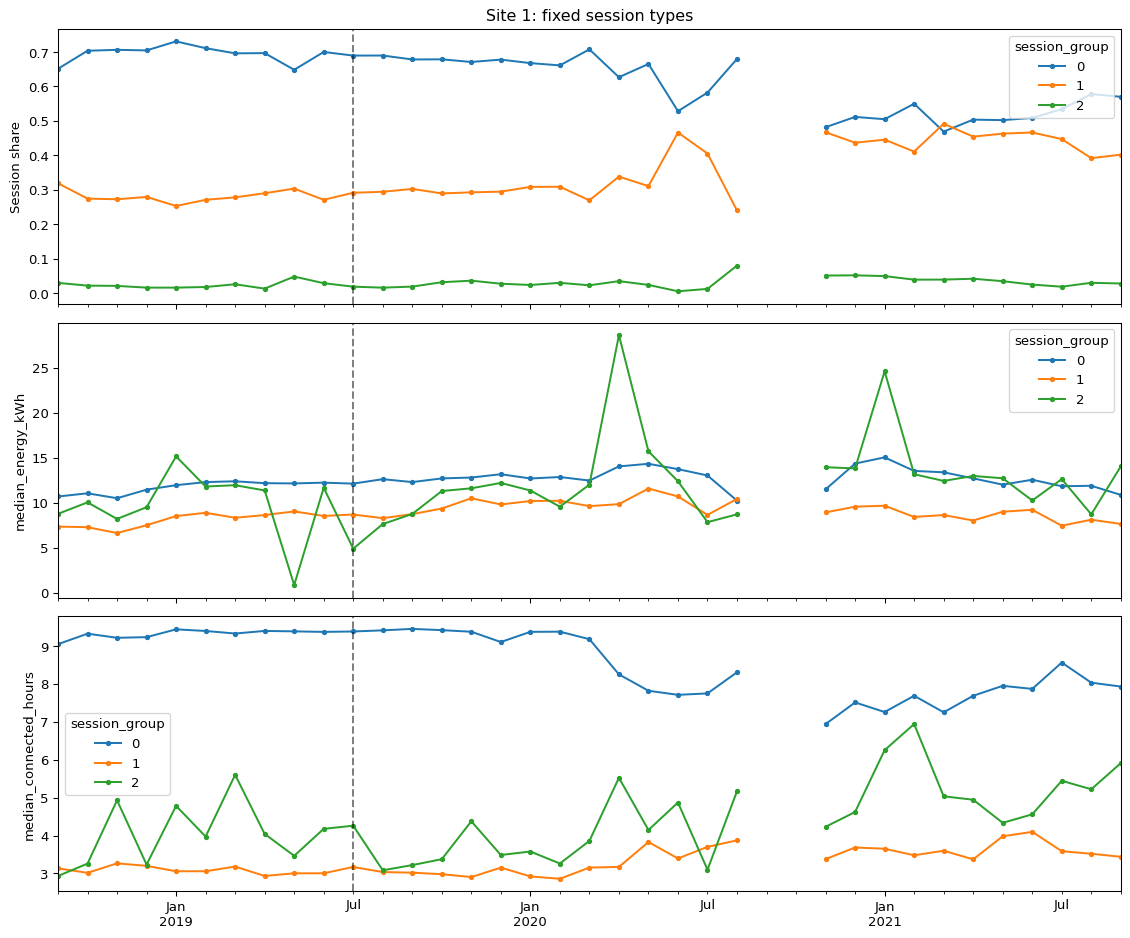

session_group,0,1,2
2018-09,520.0,1152.0,643.0
2018-10,410.0,1299.0,715.0
2018-11,185.0,901.0,223.0
2018-12,153.0,566.0,151.0
2019-01,124.0,695.0,170.0
2019-02,125.0,620.0,189.0
2019-03,134.0,632.0,188.0
2019-04,127.0,714.0,194.0
2019-05,104.0,710.0,150.0
2019-06,97.0,653.0,133.0


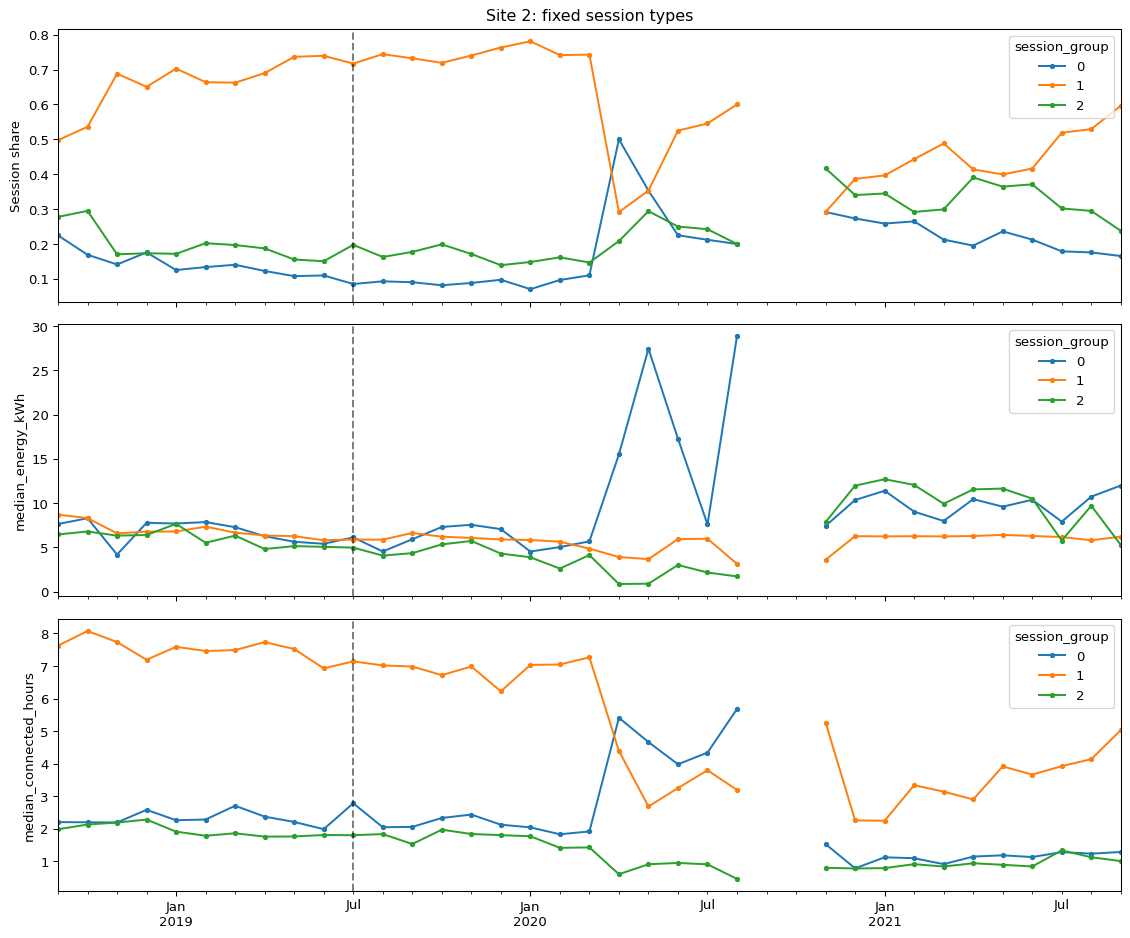

Result table is collapsed. Expand it in an HTML-capable notebook viewer.

In [ ]:
# Fixed site-specific session types over time; no refitting on future months.
site_history = {}
site_monthly = {}
for site in [1, 2]:
    data = sessions.loc[sessions["siteID"].eq(site)
                        & sessions["date"].ge(reference_start)
                        & sessions["connected_duration_hours"].gt(0)].copy()
    data["log_duration"] = np.log1p(data["connected_duration_hours"])
    data["log_energy"] = np.log1p(data["kWhDelivered"])
    fitted = site_models[site]
    values = fitted["scaler"].transform(data[session_features])
    data["session_group"] = fitted["model"].predict(values)
    data["month"] = data["date"].dt.to_period("M")
    months = pd.period_range(data["month"].min(), data["month"].max(), freq="M")
    counts = pd.crosstab(data["month"], data["session_group"]).reindex(
        columns=range(fitted["k"]), fill_value=0
    ).reindex(months)
    shares = counts.div(counts.sum(axis=1, min_count=1), axis=0)
    # Zero means no type observed in a recorded month; NaN means no sessions recorded.
    monthly = data.groupby(["month", "session_group"]).agg(
        sessions=("sessionID", "size"),
        median_energy_kWh=("kWhDelivered", "median"),
        median_connected_hours=("connected_duration_hours", "median")
    )
    site_history[site] = data
    site_monthly[site] = {"counts": counts, "shares": shares, "profiles": monthly}
    print(f"Site {site}: monthly session counts by fixed type")
    display_table(counts)
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    shares.plot(ax=axes[0], marker=".", ylabel="Session share", title=f"Site {site}: fixed session types")
    for ax, feature in zip(axes[1:], ["median_energy_kWh", "median_connected_hours"]):
        monthly[feature].unstack().reindex(months).plot(ax=ax, marker=".", ylabel=feature)
    for ax in axes:
        ax.axvline(float(pd.Period("2019-07", freq="M").ordinal), color="black", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

# Reference-to-test changes: same calendar windows at both sites.
period_comparison = []
for site, data in site_history.items():
    for name, start, end in [("Reference", reference_start, reference_end),
                              ("Test", stability_end, test_end)]:
        window = data.loc[data["date"].ge(start) & data["date"].lt(end)]
        table = window.groupby("session_group").agg(
            sessions=("sessionID", "size"), median_energy_kWh=("kWhDelivered", "median"),
            median_connected_hours=("connected_duration_hours", "median")
        ).reindex(range(site_models[site]["k"]))
        table["sessions"] = table["sessions"].fillna(0).astype(int)
        table["share_pct"] = table["sessions"] / len(window) * 100
        table["site"], table["period"] = site, name
        period_comparison.append(table.reset_index())
period_comparison = pd.concat(period_comparison, ignore_index=True)
display_table(period_comparison.set_index(["site", "session_group", "period"]).round(2))

**Figure interpretation — temporal session-pattern changes.** Each site's three panels show fixed-type shares, within-type median energy and within-type median connection duration. Reference centroids remain fixed; the dashed line marks the end of reference fitting. Gaps indicate missing observations, not zero shares or demand.

From the reference period to October–December 2019, site 1's morning/long-connection share changes modestly from 69.54% to 67.62%. Its afternoon/shorter type increases in median energy from 8.18 to 9.86 kWh while median duration remains near three hours. Site 2's morning/long-connection share rises from 62.65% to 73.83%, while its weekend share falls from 15.61% to 8.82%. Within its morning type, median energy falls from 7.03 to 6.08 kWh and median duration from 7.59 to 6.68 hours.

Both composition and within-type characteristics change. These are descriptive differences between unequal seasonal windows, not estimates of causal preference change. Low-count months after 2020 require particular caution.

### RQ2 supplementary analysis — Identified site 1 users

Apply the same scaler and centroids in every quarter to keep labels comparable. Profiles require at least five sessions. Low-frequency users and anonymous sessions are therefore not represented. Missing whole months flag incomplete coverage; observed months may still contain partial gaps. No activity recorded does not establish user departure.

group,0,1
quarter,,
2018Q4,39,100
2019Q1,55,103
2019Q2,66,111
2019Q3,69,108
2019Q4,81,113
2020Q1,66,115
2020Q2,29,19
2020Q3,19,18
2020Q4,23,13


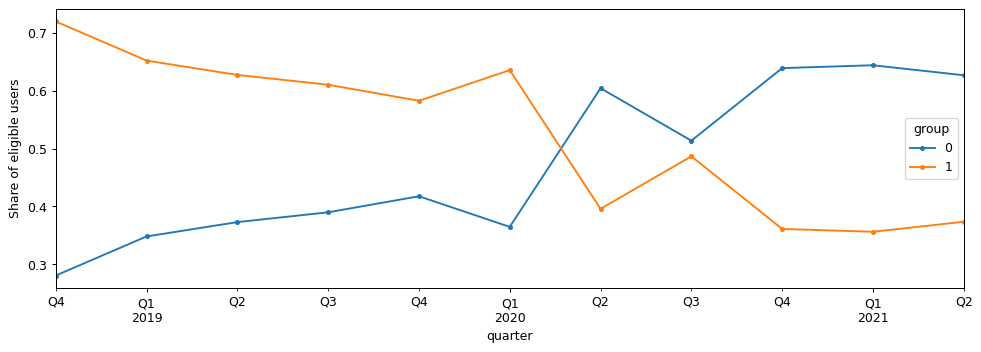

,eligible_users,mean_energy,mean_duration,mean_frequency,months_with_records
quarter,,,,,
2018Q4,139,14.796801,7.243472,7.207128,3
2019Q1,158,15.561712,7.043128,8.067436,3
2019Q2,177,15.768839,6.970129,8.042590,3
2019Q3,177,15.134495,6.816905,7.693487,3
2019Q4,194,15.700501,6.543565,6.910172,3
2020Q1,181,15.475693,6.666135,6.279317,3
2020Q2,48,16.524986,5.662754,5.288934,3
2020Q3,37,14.846600,6.024604,3.764450,2
2020Q4,36,14.427379,5.754702,4.098770,2


In [14]:
quarter_profiles = []
for quarter in pd.period_range("2018Q4", "2021Q2", freq="Q"):
    profile = user_profiles(users, quarter.start_time, (quarter + 1).start_time)
    if not profile.empty:
        profile["group"] = cluster_model.predict(scaler.transform(profile[profile_features]))
        profile["quarter"] = quarter
        quarter_profiles.append(profile.reset_index())
quarter_profiles = pd.concat(quarter_profiles, ignore_index=True)
group_counts = pd.crosstab(quarter_profiles["quarter"], quarter_profiles["group"])
group_shares = group_counts.div(group_counts.sum(axis=1), axis=0)
display_table(group_counts)
group_shares.plot(figsize=(11, 4), marker=".", ylabel="Share of eligible users")
plt.tight_layout()
plt.show()

coverage = monthly_sessions[1].groupby(monthly_sessions.index.asfreq("Q")).count()
quarter_summary = quarter_profiles.groupby("quarter").agg(
    eligible_users=("userID", "nunique"), mean_energy=("energy", "mean"),
    mean_duration=("duration", "mean"), mean_frequency=("frequency", "mean")
)
quarter_summary["months_with_records"] = coverage
display_table(quarter_summary)

**Figure interpretation — eligible-user composition at site 1.** The lines show shares among users with at least five recorded sessions per quarter, not the full population. Eligible counts fall from 181 in 2020Q1 to 48 in 2020Q2, and the balance shifts toward the later-arrival/shorter-connection group. Such a shift may reflect changing eligibility and participation as well as individual behavior. Quarters with fewer than three recorded months are explicitly flagged; three recorded months do not guarantee complete daily coverage.

In [15]:
# Adjacent-quarter changes among the same eligible users.
changes = []
transitions = {}
quarters = sorted(quarter_profiles["quarter"].unique())
for previous, current in zip(quarters[:-1], quarters[1:]):
    if current.ordinal - previous.ordinal != 1:
        continue
    before = quarter_profiles.loc[quarter_profiles["quarter"].eq(previous)].set_index("userID")
    after = quarter_profiles.loc[quarter_profiles["quarter"].eq(current)].set_index("userID")
    matched = before.index.intersection(after.index)
    if len(matched) == 0:
        continue
    transitions[str(current)] = pd.crosstab(
        before.loc[matched, "group"], after.loc[matched, "group"], normalize="index"
    )
    changes.append({
        "quarter": current, "matched_users": len(matched),
        "newly_eligible": len(after.index.difference(before.index)),
        "no_longer_eligible": len(before.index.difference(after.index)),
        "group_switch_share": before.loc[matched, "group"].ne(after.loc[matched, "group"]).mean(),
        "within_user_energy_change": (after.loc[matched, "energy"] - before.loc[matched, "energy"]).mean(),
        "within_user_duration_change": (after.loc[matched, "duration"] - before.loc[matched, "duration"]).mean(),
        "both_quarters_covered": coverage.get(previous, 0) == 3 and coverage.get(current, 0) == 3
    })
display_table(pd.DataFrame(changes).set_index("quarter"))

,matched_users,newly_eligible,no_longer_eligible,group_switch_share,within_user_energy_change,within_user_duration_change,both_quarters_covered
quarter,,,,,,,
2019Q1,116,42,23,0.120690,1.238245,0.046048,True
2019Q2,139,38,19,0.100719,-0.226723,-0.119239,True
2019Q3,146,31,31,0.075342,-0.129104,-0.195985,True
2019Q4,148,46,29,0.094595,0.633661,-0.182783,True
2020Q1,144,37,50,0.076389,-0.092214,0.170917,True
2020Q2,40,8,141,0.325000,-1.215728,-1.140494,True
2020Q3,24,13,24,0.208333,-0.416132,0.062744,False
2020Q4,21,15,16,0.285714,-0.093011,-0.391922,False
2021Q1,33,40,3,0.151515,0.111325,0.025677,False


**Matched-user finding.** During 2019, adjacent-quarter group-switch shares range from approximately 7.5% to 12.1%. In 2020Q2 the share reaches 32.5%, but only 40 users remain matched. For these users, mean session energy decreases by 1.22 kWh and mean connection duration by 1.14 hours. This is evidence of change in the observed matched subset, not a population-wide effect. Newly eligible and no-longer-eligible users are threshold categories, not confirmed entrants and departures.

### Change decomposition for reference users

Hold each reference user's group fixed. For represented groups, decompose the change in the user-weighted mean energy as

Δμ = Σₖ Δπₖ(μₖ,₁ + μₖ,₀)/2 + Σₖ Δμₖ(πₖ,₁ + πₖ,₀)/2.

The first term is between-group composition change; the second is within-group mean change. The latter can still reflect changing users inside a group, so the matched-user results above are needed separately. This is descriptive, not causal.

In [16]:
fixed = quarter_profiles.join(reference["group"].rename("reference_group"), on="userID")
fixed = fixed.dropna(subset=["reference_group"])
decomposition = []
for previous, current in zip(quarters[:-1], quarters[1:]):
    if current.ordinal - previous.ordinal != 1:
        continue
    before = fixed.loc[fixed["quarter"].eq(previous)].groupby("reference_group")["energy"].agg(["size", "mean"])
    after = fixed.loc[fixed["quarter"].eq(current)].groupby("reference_group")["energy"].agg(["size", "mean"])
    if len(before) != best_k or len(after) != best_k:
        continue
    p0, p1 = before["size"] / before["size"].sum(), after["size"] / after["size"].sum()
    composition = ((p1 - p0) * (after["mean"] + before["mean"]) / 2).sum()
    within = ((after["mean"] - before["mean"]) * (p1 + p0) / 2).sum()
    total = (p1 * after["mean"]).sum() - (p0 * before["mean"]).sum()
    decomposition.append({"quarter": current, "composition_kWh": composition,
                          "within_group_kWh": within, "total_kWh": total,
                          "both_quarters_covered": coverage.get(previous, 0) == 3 and coverage.get(current, 0) == 3})
decomposition = pd.DataFrame(decomposition).set_index("quarter")
assert np.allclose(decomposition["composition_kWh"] + decomposition["within_group_kWh"], decomposition["total_kWh"])
display_table(decomposition)

,composition_kWh,within_group_kWh,total_kWh,both_quarters_covered
quarter,,,,
2019Q1,-0.233304,1.147571,0.914266,True
2019Q2,-0.004148,0.331618,0.327470,True
2019Q3,-0.034189,-0.083565,-0.117754,True
2019Q4,-0.128229,0.646226,0.517997,True
2020Q1,0.126951,-1.335614,-1.208664,True
2020Q2,0.586538,1.691932,2.278470,True
2020Q3,-0.459193,-1.436829,-1.896023,False
2020Q4,0.055298,-1.489297,-1.433998,False
2021Q1,-0.010296,0.265003,0.254707,False


**Decomposition finding.** For the eligible reference-user cohort, the 2020Q2 increase in user-weighted mean energy is 2.28 kWh: 0.59 from between-group composition and 1.69 from within-group mean changes. This can coexist with declining energy among matched users because the samples differ and within-group membership can change. The within-group term is not a pure individual behavioral effect. Periods with coverage gaps should not support strong trend claims.

## RQ3 — Cross-site pattern and predictive transfer

Predict delivered energy at connection using calendar features available at both sites. Exclude user IDs, departure time, final duration and user requests. Both sites share the same train/test dates and model settings. Compare local, source-only, pooled, and source plus one month of target data. Adaptation uses June 2019 only; compare with a target-June-only baseline. This tests predictive transfer, not identical user populations or causal site effects.

### RQ3a — Transfer of descriptive session patterns

Apply site 1's fixed reference model to later sessions at both sites, then repeat using site 2's model. Compare source-site and target-site test periods under the same source scaler and centroids. This avoids treating independently generated cluster numbers as equivalent.

Report cluster shares, nearest-centroid distance, and the fraction beyond the source reference distance's 95th percentile. Larger distances suggest weaker fit under that source representation, not a statistical proof of a novel behavior. The reference threshold is in-sample and descriptive. Compare distances within a source-model row only; scales differ between source models. Full-session outcomes are allowed here because this is retrospective pattern analysis, not arrival-time prediction.

Source model 1: cross-site total variation in test type shares = 0.335
Source model 2: cross-site total variation in test type shares = 0.078


Result table is collapsed. Expand it in an HTML-capable notebook viewer.

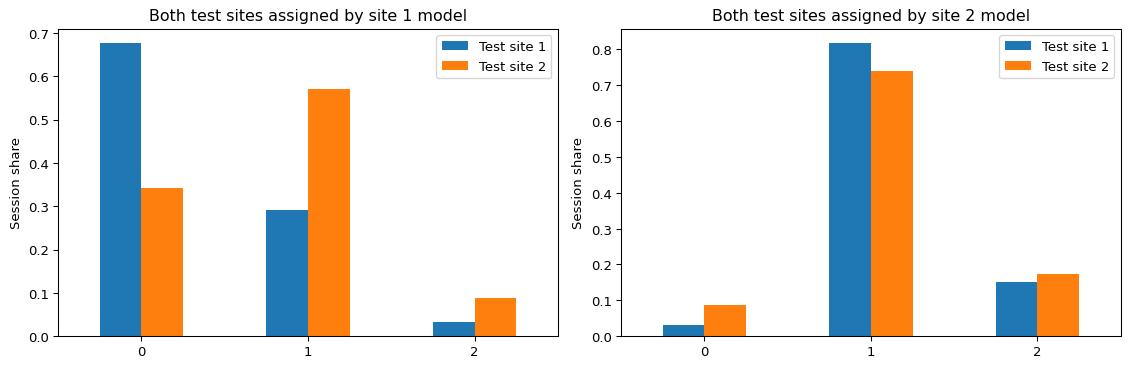

In [ ]:
pattern_transfer = []
pattern_shares = {}
for source in [1, 2]:
    fitted = site_models[source]
    reference_data = site_assignments[source]
    reference_values = fitted["scaler"].transform(reference_data[session_features])
    reference_distance = cdist(reference_values, fitted["model"].cluster_centers_).min(axis=1)
    threshold = np.quantile(reference_distance, 0.95)
    for target in [1, 2]:
        data = site_history[target]
        data = data.loc[data["date"].ge(stability_end) & data["date"].lt(test_end)]
        values = fitted["scaler"].transform(data[session_features])
        distances = cdist(values, fitted["model"].cluster_centers_)
        labels = distances.argmin(axis=1)
        nearest = distances.min(axis=1)
        shares = pd.Series(labels).value_counts(normalize=True).reindex(range(fitted["k"]), fill_value=0)
        pattern_shares[(source, target)] = shares
        pattern_transfer.append({"source_model": source, "test_site": target,
            "sessions": len(data), "mean_distance": nearest.mean(),
            "source_reference_p95": threshold, "beyond_reference_p95_share": (nearest > threshold).mean()})
pattern_transfer = pd.DataFrame(pattern_transfer).set_index(["source_model", "test_site"])
display_table(pattern_transfer.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, source in zip(axes, [1, 2]):
    shares = pd.DataFrame({f"Test site {target}": pattern_shares[(source, target)] for target in [1, 2]})
    shares.plot.bar(ax=ax, rot=0, ylabel="Session share", title=f"Both test sites assigned by site {source} model")
    distance = 0.5 * np.abs(shares.iloc[:, 0] - shares.iloc[:, 1]).sum()
    print(f"Source model {source}: cross-site total variation in test type shares = {distance:.3f}")
plt.tight_layout()
plt.show()

**Figure interpretation — directional pattern transfer.** Each panel applies one source model to both sites' test sessions, so the bars share a common labeling rule within that panel. Total variation between the two distributions is 0.335 under the site 1 model and 0.078 under the site 2 model. Using the site 1 model, 24.3% of site 2 test sessions exceed its reference distance threshold, compared with 6.1% at site 1. Using the site 2 model, the corresponding shares are 1.7% at site 1 and 3.9% at site 2.

The representation-dependent asymmetry suggests unequal descriptive coverage. It does not prove that the site 2 model is universally more transferable: scalers, partitions and thresholds differ. Distance exceedance is descriptive, not a significance test or proof of a new behavior type.

### RQ3b — Arrival-time predictive transfer

Retain the common-information energy prediction benchmark below. Actual energy, final connection duration and outcome-derived session labels are excluded from its inputs. Descriptive cluster transfer and predictive transfer answer different questions and are reported separately.

Result table is collapsed. Expand it in an HTML-capable notebook viewer.

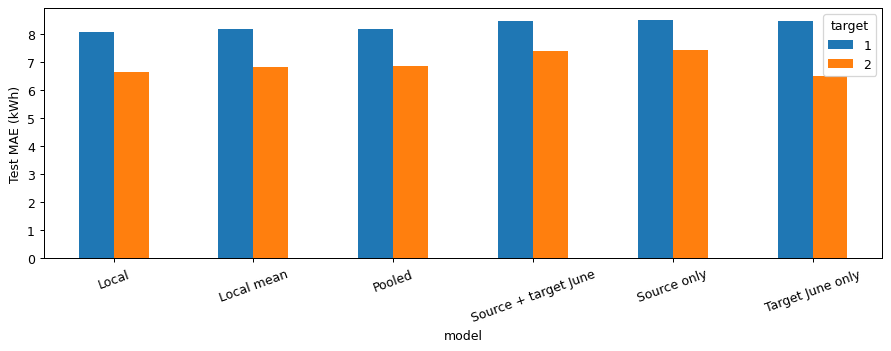

In [17]:
prediction_features = ["arrival_sin", "arrival_cos", "weekend", "month_sin", "month_cos"]
train = sessions.loc[sessions["date"].ge(reference_start) & sessions["date"].lt(reference_end)]
test = sessions.loc[sessions["date"].ge(stability_end) & sessions["date"].lt(test_end)]
transfer_scores = []
transfer_errors = []
for target in [1, 2]:
    source = 3 - target
    target_test = test.loc[test["siteID"].eq(target)]
    target_train = train.loc[train["siteID"].eq(target)]
    source_train = train.loc[train["siteID"].eq(source)]
    adaptation = target_train.loc[target_train["date"].ge("2019-06-01")]
    training_sets = {
        "Local": target_train, "Source only": source_train, "Pooled": train,
        "Source + target June": pd.concat([source_train, adaptation]),
        "Target June only": adaptation
    }
    for name, training in training_sets.items():
        model = RandomForestRegressor(n_estimators=100, min_samples_leaf=20,
                                      random_state=42, n_jobs=-1)
        model.fit(training[prediction_features], training["kWhDelivered"])
        prediction = model.predict(target_test[prediction_features])
        error = np.abs(target_test["kWhDelivered"].to_numpy() - prediction)
        transfer_scores.append({"target": target, "model": name,
                                "train_sessions": len(training), "test_sessions": len(target_test),
                                "MAE_kWh": error.mean()})
        transfer_errors.append(pd.DataFrame({"target": target, "model": name,
            "day": target_test["date"].dt.normalize().to_numpy(), "error": error}))
    transfer_scores.append({"target": target, "model": "Local mean",
        "train_sessions": len(target_train), "test_sessions": len(target_test),
        "MAE_kWh": mean_absolute_error(target_test["kWhDelivered"],
                       np.repeat(target_train["kWhDelivered"].mean(), len(target_test)))})
transfer_scores = pd.DataFrame(transfer_scores)
display_table(transfer_scores.set_index(["target", "model"]))
transfer_scores.pivot(index="model", columns="target", values="MAE_kWh").plot.bar(
    figsize=(10, 4), ylabel="Test MAE (kWh)", rot=20
)
plt.tight_layout()
plt.show()

**Figure interpretation — predictive transfer errors.** Lower bars mean lower test MAE. Local models achieve 8.07 kWh at site 1 and 6.65 kWh at site 2; source-only models achieve 8.50 and 7.44 kWh. Direct transfer therefore increases MAE by approximately 5.2% and 11.8%. Pooled training does not outperform local training. At site 2, the June-only local baseline has the lowest observed MAE (6.48 kWh), a result requiring further temporal validation rather than a general claim that less data is better.

Local models improve only modestly over local mean baselines, indicating limited predictive information in the shared calendar features. Descriptive session labels use outcomes and are deliberately excluded from arrival-time predictors.

In [18]:
# Paired day-bootstrap uncertainty for source-only minus local MAE.
# Conditions on fitted models; does not include training uncertainty.
transfer_errors = pd.concat(transfer_errors, ignore_index=True)
rng = np.random.default_rng(42)
for target in [1, 2]:
    daily = transfer_errors.loc[transfer_errors["target"].eq(target)].groupby(
        ["day", "model"]
    )["error"].agg(["sum", "size"])
    sums = daily["sum"].unstack()
    counts = daily["size"].unstack()["Local"]
    difference = (sums["Source only"] - sums["Local"]).to_numpy()
    indices = rng.integers(0, len(counts), size=(1000, len(counts)))
    draws = difference[indices].sum(axis=1) / counts.to_numpy()[indices].sum(axis=1)
    print("Target", target, "source minus local MAE:", difference.sum() / counts.sum(),
          "95% day-bootstrap interval:", np.quantile(draws, [0.025, 0.975]))

Target 1 source minus local MAE: 0.4220705441323108 95% day-bootstrap interval: [0.3373117  0.50100452]
Target 2 source minus local MAE: 0.7841130132226295 95% day-bootstrap interval: [0.64384019 0.93584331]


**Uncertainty finding.** Source-only minus local MAE is +0.422 kWh at site 1 (95% day-bootstrap interval: 0.337–0.501) and +0.784 kWh at site 2 (0.644–0.936). Both intervals remain above zero, supporting worse direct transfer in this test window conditional on the fitted models. The bootstrap does not capture training uncertainty, all cross-day dependence or performance in other time windows.

## Interpretation limits

- Group quality, future stability and predictive value are separate results; a high silhouette alone is insufficient.
- Group transitions may reflect sparse samples or clustering boundaries. Repeat with alternative K and minimum-session thresholds before making substantive claims.
- RQ2 estimates are conditional on eligible observed users. Missing records, access changes and user turnover cannot be fully separated without operational metadata.
- Site 2 is evaluated as anonymous sessions, regardless of partially populated ID fields.
- RQ3 uses a deliberately simple common-information benchmark. Pooled/adapted models also differ in training sample size; improvement alone does not isolate transferable structure.
- Delivered energy reflects both user demand and charging-system constraints. No causal or psychological interpretation is established by these analyses.

Main RQ2 results describe session populations at both sites. Supplementary user-level estimates apply only to eligible, identified site 1 users. Neither session-type shifts nor cross-site distances establish individual behavioral change or causal site effects.

## Answers to the research questions

### RQ1 — What distinct charging-session patterns can be identified at each site?

Both sites show three exploratory session types under the current feature set and K-selection rule. A weekday morning/long-connection pattern dominates both sites (69.5% at site 1; 62.6% at site 2). The shorter weekday pattern occurs mainly in the afternoon at site 1 and in the evening at site 2. Weekend sessions account for 2.4% and 15.6%, respectively. The sites share broad structure but differ in timing, duration and prevalence. These are session patterns, not verified user identities or psychological types; the strong weekend-feature influence requires sensitivity analysis.

### RQ2 — How do pattern prevalence and within-type characteristics change over time?

Both dimensions change. Between the reference period and 2019Q4, site 1's morning-type share remains relatively stable (69.54% to 67.62%), while its afternoon type's median energy rises from 8.18 to 9.86 kWh. At site 2, the morning-type share rises from 62.65% to 73.83%, yet its median energy falls from 7.03 to 6.08 kWh and median duration from 7.59 to 6.68 hours. Consequently, aggregate means or type shares alone are insufficient. Identified-user analysis at site 1 further shows that aggregate and matched-user changes may differ. Seasonality, operations and coverage are not causally separated.

### RQ3 — To what extent do patterns and prediction models transfer across sites?

Descriptive pattern matching is asymmetric and depends on the source representation. Predictively, direct transfer performs worse than local training in both directions: MAE rises from 8.07 to 8.50 kWh at site 1 and from 6.65 to 7.44 kWh at site 2. Day-bootstrap intervals for these increases exclude zero conditional on fitted models. Simple pooling does not improve on the local models. Shared behavioral patterns therefore do not guarantee predictive transfer under the current calendar features, model and test period; these results do not rule out more effective adaptation methods.

### Scope of the evidence

Reference fitting uses September 2018–June 2019 and held-out comparisons use October–December 2019. The longer time series is descriptive. Session-level findings apply to recorded sessions, while individual findings apply only to eligible identified users at site 1. All reported values correspond to the saved run and must be reviewed after changing data, thresholds or models.
